# LeNet: Complete Software and Systolic Hardware Answers

**Matin Firoozbakht** | [@matinfirooz](https://github.com/matinfirooz)

The full checkpoint, dataset, RTL and actual results are included in the companion ZIP. Open this notebook from its extracted project directory. All computations and diagrams describe the implemented design. Saved evidence is checked against source and data hashes.

Default execution loads the trained checkpoint. Set `RETRAIN=True` and `RUN_RTL=True` to retrain and requalify the design. Vivado physical metrics are unmeasured; supplied scripts run that flow locally.


In [1]:
import json
import sys
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Image, Code, Markdown
ROOT=Path.cwd()
if not (ROOT/'software/model.py').exists():
    raise FileNotFoundError('Extract HW3_Matin_Firoozbakht.zip and open this notebook from that project directory.')
sys.path.insert(0,str(ROOT))
RETRAIN=False
RUN_RTL=False
print('Matin Firoozbakht | @matinfirooz')


Matin Firoozbakht | @matinfirooz


## 1. Specification and implementation scope

The CNN layer table defines the implemented network. It includes C5, so there are
three convolution operations. C3 is densely connected. Average-pooling stages have
no trainable scale or bias and apply tanh after the arithmetic mean. The unrelated
MLP instructions in the later PDF pages are not mixed into this CNN. Full decisions
and the source PDF are in [docs/SPECIFICATION.md](docs/SPECIFICATION.md).

| Layer | Operation | Output | Kernel/shape | Parameters | MACs | Tiles |
| --- | --- | --- | --- | --- | --- | --- |
| C1 | Convolution + tanh | 6 x 28 x 28 | 6x1x5x5 | 156 | 117600 | 1570 |
| S2 | Average pool + tanh | 6 x 14 x 14 | 2x2 / stride 2 | 0 | 0 | 0 |
| C3 | Convolution + tanh | 16 x 10 x 10 | 16x6x5x5 | 2416 | 240000 | 2400 |
| S4 | Average pool + tanh | 16 x 5 x 5 | 2x2 / stride 2 | 0 | 0 | 0 |
| C5 | Convolution + tanh | 120 x 1 x 1 | 120x16x5x5 | 48120 | 48000 | 1920 |
| F6 | Dense + tanh | 84 | 84x120 | 10164 | 10080 | 408 |
| F7 | Dense + softmax | 10 | 10x84 | 850 | 840 | 34 |

The total is 61,706 parameters (61,470 weights and 236 biases), 416,520 useful MACs,
and 6,332 systolic tile calls per image. The two pools generate 1,576 outputs;
8,084 intermediate activation values are stored across the six non-output stages.


## 2. Dataset, preprocessing and training

Fashion-MNIST has 60,000 official training and 10,000 official test images, each
28x28 u8. MD5 and SHA-256 records accompany the exact downloaded files. The official
training partition is split class-wise into 54,000 training and 6,000 validation
examples using seed 42. The official test set is held out from optimization and
checkpoint selection. Each class contributes 5,400 training and 600 validation images.

Input pixels are divided by 255, then padded with two zeros on each side to 32x32.
The HDL reads raw pixels from the original binary IDX test file in its testbench;
the synthesizable frontend performs the normalization and padding-address mapping.
It first clears all 1,024 input words, then writes pixel (y,x) to (y+2)*32+(x+2).

The PyTorch forward path uses tanh after C1, S2, C3, S4, C5 and F6. Training passes
raw F7 logits to cross-entropy, which supplies the stable softmax/log-loss operation.
Inference explicitly evaluates softmax. AdamW uses batch size 256, learning rate
0.001, weight decay 0.0001, and a factor-0.5 learning-rate reduction after epochs
10 and 16. Model seed is 7, shuffle seed is 42, and deterministic CPU operations
are enabled. The selected checkpoint is the minimum validation-cross-entropy epoch.

The measured run completed 20 epochs, selected epoch
20, and recorded 104.92 seconds for the training/final-evaluation
script. Training used 4 CPU threads and PyTorch 2.5.1+cpu.
The full checkpoint, every floating-point parameter, every integer parameter,
split indices, epoch curves and test predictions are included.

| Implementation | Official test images | Correct | Accuracy |
| --- | --- | --- | --- |
| PyTorch float32 | 10000 | 8884 | 88.84% |
| Integer Q12 reference | 10000 | 8884 | 88.84% |

Accuracy is correct classifications divided by the number of test examples.
Here the float count is 8884/10000; the integer count is
8884/10000. Class selection uses the smallest index attaining the maximum
full logit. The two systems disagree on 11 predictions,
so equal aggregate accuracy does not mean identical predictions.


,epoch,train_cross_entropy,train_accuracy,validation_cross_entropy,validation_accuracy,learning_rate,seconds
0,1,0.851901,0.699259,0.562804,0.793500,0.00100,5.354601
1,2,0.502304,0.818389,0.456513,0.837167,0.00100,4.980507
2,3,0.432447,0.843278,0.415991,0.848500,0.00100,5.073388
3,4,0.395318,0.856519,0.388839,0.856667,0.00100,5.212336
4,5,0.369116,0.865185,0.361472,0.865167,0.00100,5.344774
5,6,0.350905,0.871722,0.363548,0.863167,0.00100,5.310150
6,7,0.332877,0.878037,0.340926,0.873000,0.00100,4.941054
7,8,0.322859,0.881370,0.332225,0.877833,0.00100,5.587937
8,9,0.310422,0.887222,0.333715,0.875000,0.00100,5.147631
9,10,0.303603,0.888204,0.315210,0.880333,0.00100,5.298125


,n,correct,accuracy,cross_entropy
0,10000,8884,0.8884,0.311439


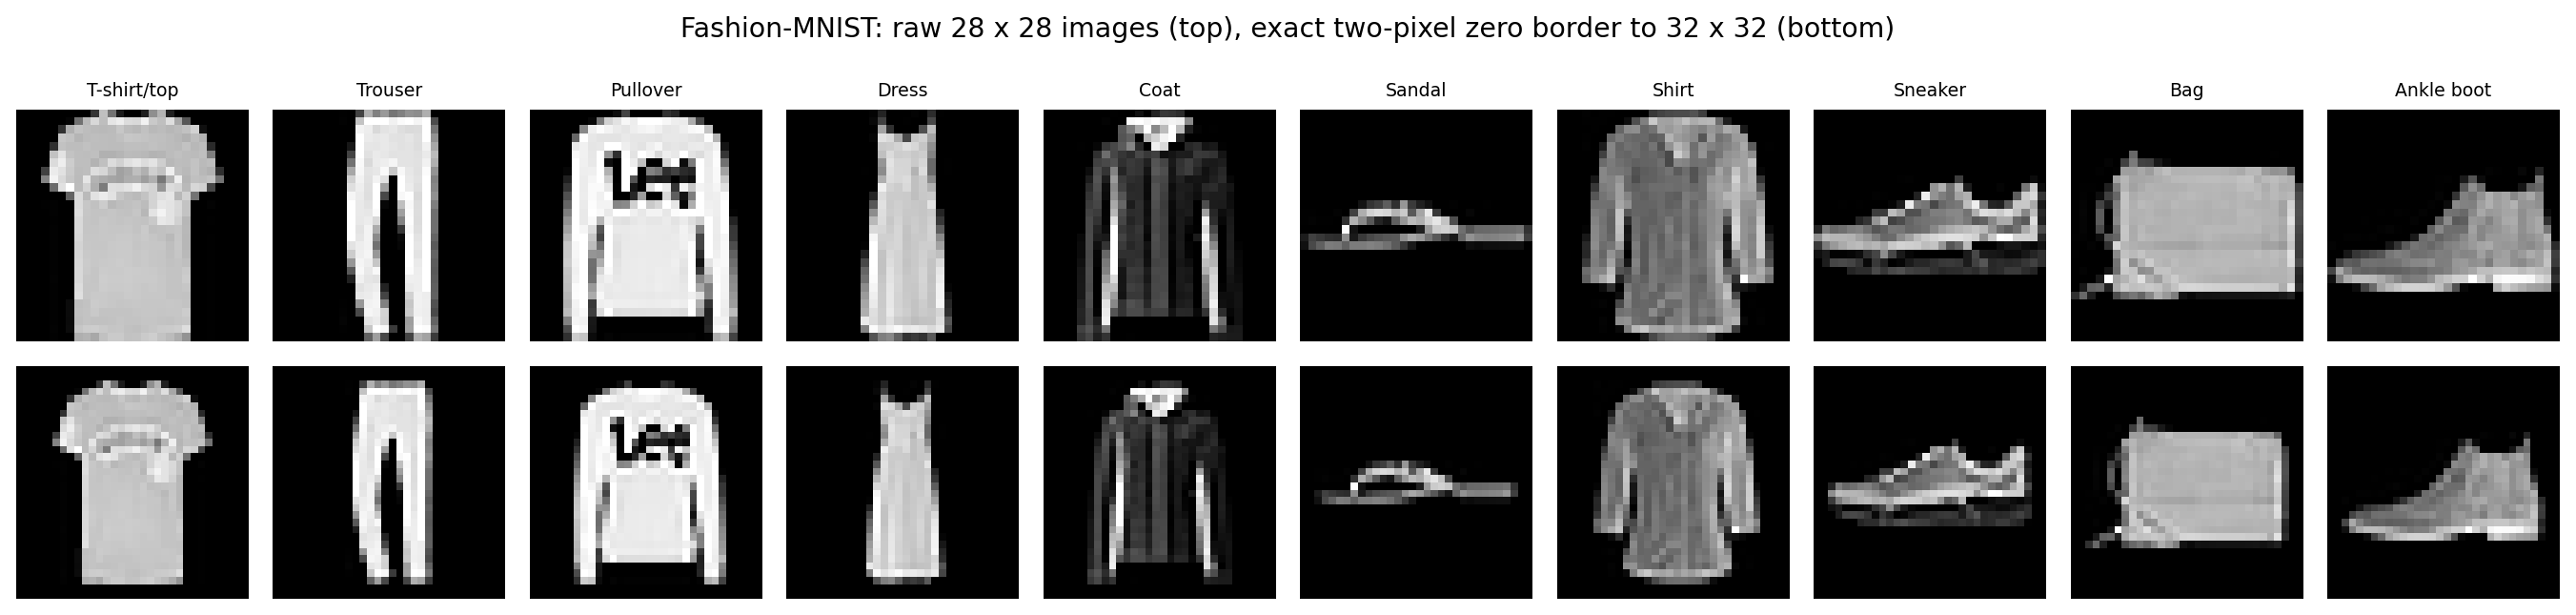

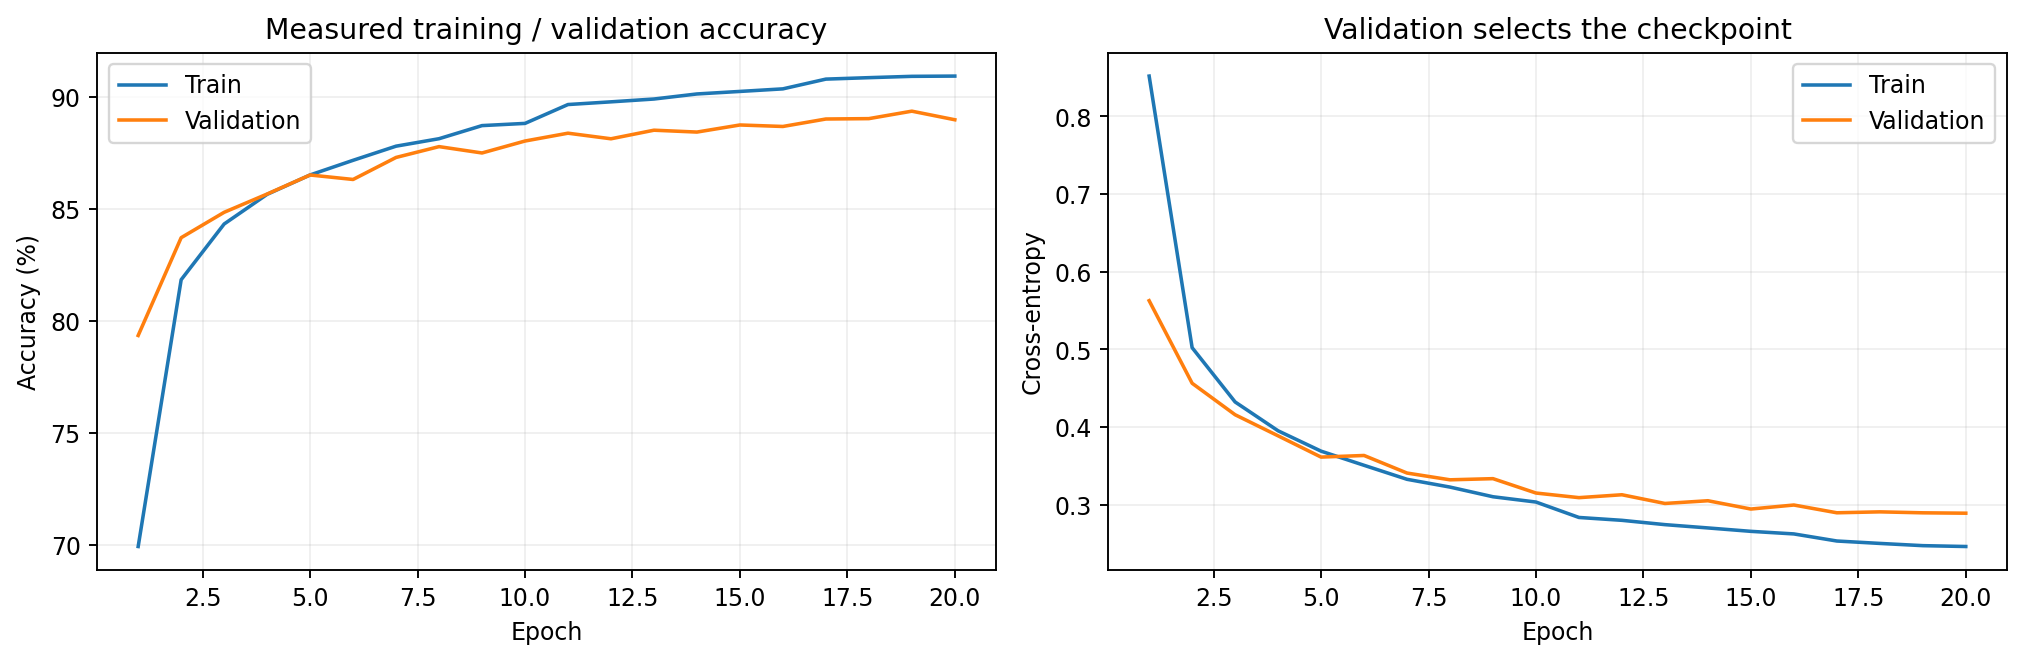

In [2]:
if RETRAIN:
    subprocess.run([sys.executable,'scripts/train.py','--epochs','20','--threads','4'],cwd=ROOT,check=True)
    subprocess.run([sys.executable,'scripts/export_evaluate.py','--rtl-images','16'],cwd=ROOT,check=True)
history=json.loads((ROOT/'results/software/training_history.json').read_text())
training=json.loads((ROOT/'results/software/training_summary.json').read_text())
display(pd.DataFrame(history))
display(pd.DataFrame([training['test']]))
for name in ['data_padding.png','training.png']:
    display(Image(filename=str(ROOT/'results/figures'/name)))


### Complete PyTorch implementation

The source follows the layer table, including tanh after average pooling. Cross-entropy receives raw logits; inference emits softmax scores.


In [3]:
for name in ['software/data.py','software/model.py','scripts/train.py']:
    display(Markdown('#### '+name))
    display(Code((ROOT/name).read_text(),language='python'))


#### software/data.py

"""Official Fashion-MNIST IDX files, verified downloads and disjoint splits."""
import gzip
import hashlib
import json
import struct
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np

FILES={
 'train-images-idx3-ubyte.gz':'8d4fb7e6c68d591d4c3dfef9ec88bf0d',
 'train-labels-idx1-ubyte.gz':'25c81989df183df01b3e8a0aad5dffbe',
 't10k-images-idx3-ubyte.gz':'bef4ecab320f06d8554ea6380940ec79',
 't10k-labels-idx1-ubyte.gz':'bb300cfdad3c16e7a12a480ee83cd310',
}
BASE='https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'
CLASSES=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']

def download(root):
    root=Path(root);root.mkdir(parents=True,exist_ok=True)
    def one(item):
        name,expected=item;p=root/name
        if not p.exists():
            with urllib.request.urlopen(BASE+name,timeout=90) as response:p.write_bytes(response.read())
        data=p.read_bytes()
        if hashlib.md5(data).hexdigest()!=expected:raise ValueError('Checksum mismatch: '+name)
        if name.startswith('t10k'): (root/name.removesuffix('.gz')).write_bytes(gzip.decompress(data))
        return {'file':name,'source':BASE+name,'bytes':len(data),'md5':expected,'sha256':hashlib.sha256(data).hexdigest()}
    with ThreadPoolExecutor(max_workers=4) as pool:manifest=list(pool.map(one,FILES.items()))
    (root/'manifest.json').write_text(json.dumps(manifest,indent=2))
    return manifest

def load_idx(root,kind='train'):
    root=Path(root)
    image=gzip.decompress((root/(kind+'-images-idx3-ubyte.gz')).read_bytes())
    label=gzip.decompress((root/(kind+'-labels-idx1-ubyte.gz')).read_bytes())
    magic,n,h,w=struct.unpack('>4I',image[:16]);lm,ln=struct.unpack('>2I',label[:8])
    if (magic,lm,h,w)!=(2051,2049,28,28) or n!=ln:raise ValueError('Invalid IDX header')
    x=np.frombuffer(image,dtype=np.uint8,offset=16).reshape(n,28,28).copy()
    y=np.frombuffer(label,dtype=np.uint8,offset=8).copy()
    if len(image)!=16+n*784 or len(label)!=8+n or y.max()>9:raise ValueError('Invalid IDX payload')
    return x,y

def split_indices(labels,seed=42):
    rng=np.random.default_rng(seed);train=[];valid=[]
    for c in range(10):
        indexes=np.flatnonzero(labels==c);rng.shuffle(indexes)
        valid.extend(indexes[:600]);train.extend(indexes[600:])
    return np.sort(np.array(train,dtype=np.int64)),np.sort(np.array(valid,dtype=np.int64))

#### software/model.py

"""Dense LeNet matching the specification's layer table, including pooled tanh."""
import torch
from torch import nn

class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(1,6,5)
        self.conv3=nn.Conv2d(6,16,5)
        self.conv5=nn.Conv2d(16,120,5)
        self.fc6=nn.Linear(120,84)
        self.fc7=nn.Linear(84,10)
    def forward(self,x):
        x=torch.tanh(self.conv1(x))
        x=torch.tanh(nn.functional.avg_pool2d(x,2))
        x=torch.tanh(self.conv3(x))
        x=torch.tanh(nn.functional.avg_pool2d(x,2))
        x=torch.tanh(self.conv5(x)).flatten(1)
        return self.fc7(torch.tanh(self.fc6(x)))
    def probabilities(self,x):
        return torch.softmax(self(x),dim=1)

def prepare_pixels(raw):
    x=torch.as_tensor(raw.copy()).float().unsqueeze(1)/255.0
    return nn.functional.pad(x,(2,2,2,2),value=0.0)

#### scripts/train.py

"""Train on 54,000 images, select by 6,000 validation images, evaluate official test once."""
import argparse
import csv
import hashlib
import json
import os
import platform
import sys
from pathlib import Path
from time import perf_counter

ROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT))
import numpy as np
import torch
from software.data import download,load_idx,split_indices
from software.model import LeNet,prepare_pixels

def evaluate(model,x,y,batch=512):
    model.eval();loss=correct=0;parts=[]
    with torch.inference_mode():
        for begin in range(0,len(y),batch):
            logits=model(x[begin:begin+batch]);target=y[begin:begin+batch]
            loss+=torch.nn.functional.cross_entropy(logits,target,reduction='sum').item()
            correct+=(logits.argmax(1)==target).sum().item();parts.append(logits.numpy())
    return {'n':len(y),'correct':correct,'accuracy':correct/len(y),'cross_entropy':loss/len(y)},np.concatenate(parts)

def main():
    parser=argparse.ArgumentParser();parser.add_argument('--epochs',type=int,default=20);parser.add_argument('--threads',type=int,default=4);args=parser.parse_args()
    torch.set_num_threads(args.threads);torch.set_num_interop_threads(1)
    torch.manual_seed(7);np.random.seed(7);torch.use_deterministic_algorithms(True)
    download(ROOT/'data/fashion');raw,labels=load_idx(ROOT/'data/fashion');ti,vi=split_indices(labels)
    np.savez(ROOT/'results/software/split_indices.npz',train=ti,validation=vi)
    allx=prepare_pixels(raw);ally=torch.tensor(labels,dtype=torch.long)
    x,y=allx[ti],ally[ti];vx,vy=allx[vi],ally[vi]
    model=LeNet();count=sum(p.numel() for p in model.parameters());assert count==61706
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.0001)
    scheduler=torch.optim.lr_scheduler.MultiStepLR(optimizer,milestones=[10,16],gamma=.5)
    rng=torch.Generator().manual_seed(42);history=[];best=float('inf');best_epoch=0;started=perf_counter()
    for epoch in range(1,args.epochs+1):
        mark=perf_counter();model.train();loss=correct=0;order=torch.randperm(len(y),generator=rng)
        for begin in range(0,len(y),256):
            idx=order[begin:begin+256];optimizer.zero_grad(set_to_none=True)
            logits=model(x[idx]);value=torch.nn.functional.cross_entropy(logits,y[idx]);value.backward();optimizer.step()
            loss+=value.item()*len(idx);correct+=(logits.detach().argmax(1)==y[idx]).sum().item()
        val,_=evaluate(model,vx,vy)
        record={'epoch':epoch,'train_cross_entropy':loss/len(y),'train_accuracy':correct/len(y),'validation_cross_entropy':val['cross_entropy'],'validation_accuracy':val['accuracy'],'learning_rate':optimizer.param_groups[0]['lr'],'seconds':perf_counter()-mark}
        history.append(record)
        if val['cross_entropy']<best:
            best=val['cross_entropy'];best_epoch=epoch
            torch.save({'state_dict':model.state_dict(),'author':'Matin Firoozbakht','github':'https://github.com/matinfirooz','epoch':epoch,'architecture':'32x32 -> C1/S2/C3/S4/C5/F6/F7'},ROOT/'software/lenet_fashion_mnist.pt')
        scheduler.step();print(json.dumps(record),flush=True)
        (ROOT/'results/software/training_history.json').write_text(json.dumps(history,indent=2))
    checkpoint=torch.load(ROOT/'software/lenet_fashion_mnist.pt',map_location='cpu',weights_only=True);model.load_state_dict(checkpoint['state_dict'])
    np.savez_compressed(ROOT/'software/trained_weights.npz',**{k:v.detach().numpy() for k,v in model.state_dict().items()})
    test_raw,test_labels=load_idx(ROOT/'data/fashion','t10k');test_x=prepare_pixels(test_raw);test_y=torch.tensor(test_labels,dtype=torch.long)
    test,logits=evaluate(model,test_x,test_y);validation,_=evaluate(model,vx,vy)
    np.savez_compressed(ROOT/'results/software/float_test_outputs.npz',logits=logits,labels=test_labels,predictions=logits.argmax(1))
    with (ROOT/'results/software/training_history.csv').open('w',newline='') as f:
        writer=

In [4]:
import torch
torch.set_num_threads(1)
from software.model import LeNet, prepare_pixels
from software.data import load_idx
from software.fixed_point import infer_integer
model=LeNet()
model.load_state_dict(torch.load(ROOT/'software/lenet_fashion_mnist.pt',map_location='cpu',weights_only=True)['state_dict'])
model.eval()
raw,labels=load_idx(ROOT/'data/fashion','t10k')
q=dict(np.load(ROOT/'software/integer_weights.npz'))
with torch.inference_mode():
    probabilities=model.probabilities(prepare_pixels(raw[:4])).numpy()
integer=infer_integer(raw[:4],q,trace=True)
display(pd.DataFrame({'label':labels[:4],'float_class':probabilities.argmax(1),'integer_class':integer['predictions']}))
print('Trainable parameters:',sum(p.numel() for p in model.parameters()))
print('Intermediate values per image:',integer['trace'].shape[1])


Trainable parameters: 61706
Intermediate values per image: 8084


,label,float_class,integer_class
0,9,9,9
1,2,2,2
2,1,1,1
3,1,1,1


## 3. Convolution as a folded matrix product

For output position p, output channel n and flattened reduction coordinate k,
the operation is C[p,n] = bias[n] + sum_k A[p,k]*B[k,n]. A is an addressed view of
the input patch; the design does not store a duplicated im2col matrix. B[k,n] is
the trained channel-major kernel coefficient. Each call computes a 5x5 output tile
with a five-element reduction, then adds its 25 partial sums to 48-bit tile state.
Reduction tiles continue until K is exhausted. Bias is seeded exactly once per
output tile. Missing spatial positions, output channels and final reduction lanes
are zeroed. Only valid output coordinates are committed.

The loop order is output-channel tile N, spatial tile M, then reduction tile K.
For each tile the controller loads 25 A words and 25 B words, starts the selected
physical array, waits for done, and accumulates its result. All dense layers use
the same array with M=1. Their unused spatial lanes are masked, which reduces
utilization without changing numerical results.


## 4. Three physical dataflows

| Dataflow | PE row / column | Stationary state | Horizontal movement | Vertical movement | Result location |
| --- | --- | --- | --- | --- | --- |
| WS | k / n | B[k,n] | A | 48-bit partial sum | Bottom edge, gathered by m/n |
| OS | m / n | C[m,n] | A | B | Local PE accumulator |
| IS | m / k | A[m,k] | 48-bit partial sum | B | Right edge, gathered by m/n |

WS loads 25 local weights. Row r receives A[m,r] at wave clock m+r; forwarding
adds column delay. A matching partial sum reaches the same PE from the row above.
IS loads 25 local activations. Column c receives B[c,n] at clock n+c; forwarding
adds row delay, and partial sums advance from the left. OS injects A[m,k] at k+m
and B[k,n] at k+n; each PE receives matching operands at k+m+n.

Every PE performs a signed 16x16 product, sign extends it, and uses a signed 48-bit
addition. Valid bits follow register boundaries. Each full tile performs 125 useful
MACs over 13 wave clocks, plus one capture clock: **14 clocks per array call**, as
checked by the independent matrix-product testbench. The 6,332 calls therefore
contain 88,648 array-service clocks. Fill/drain, tails and dense M=1 tiles explain
why 25 multipliers do not imply 25 useful network MACs on every system clock.

All three designs deliberately share the same tile size and external schedule.
Their measured cycle counts therefore match under the same memory configuration.
Stationarity changes local storage, routing and switching activity; it does not
automatically establish a throughput or energy winner.


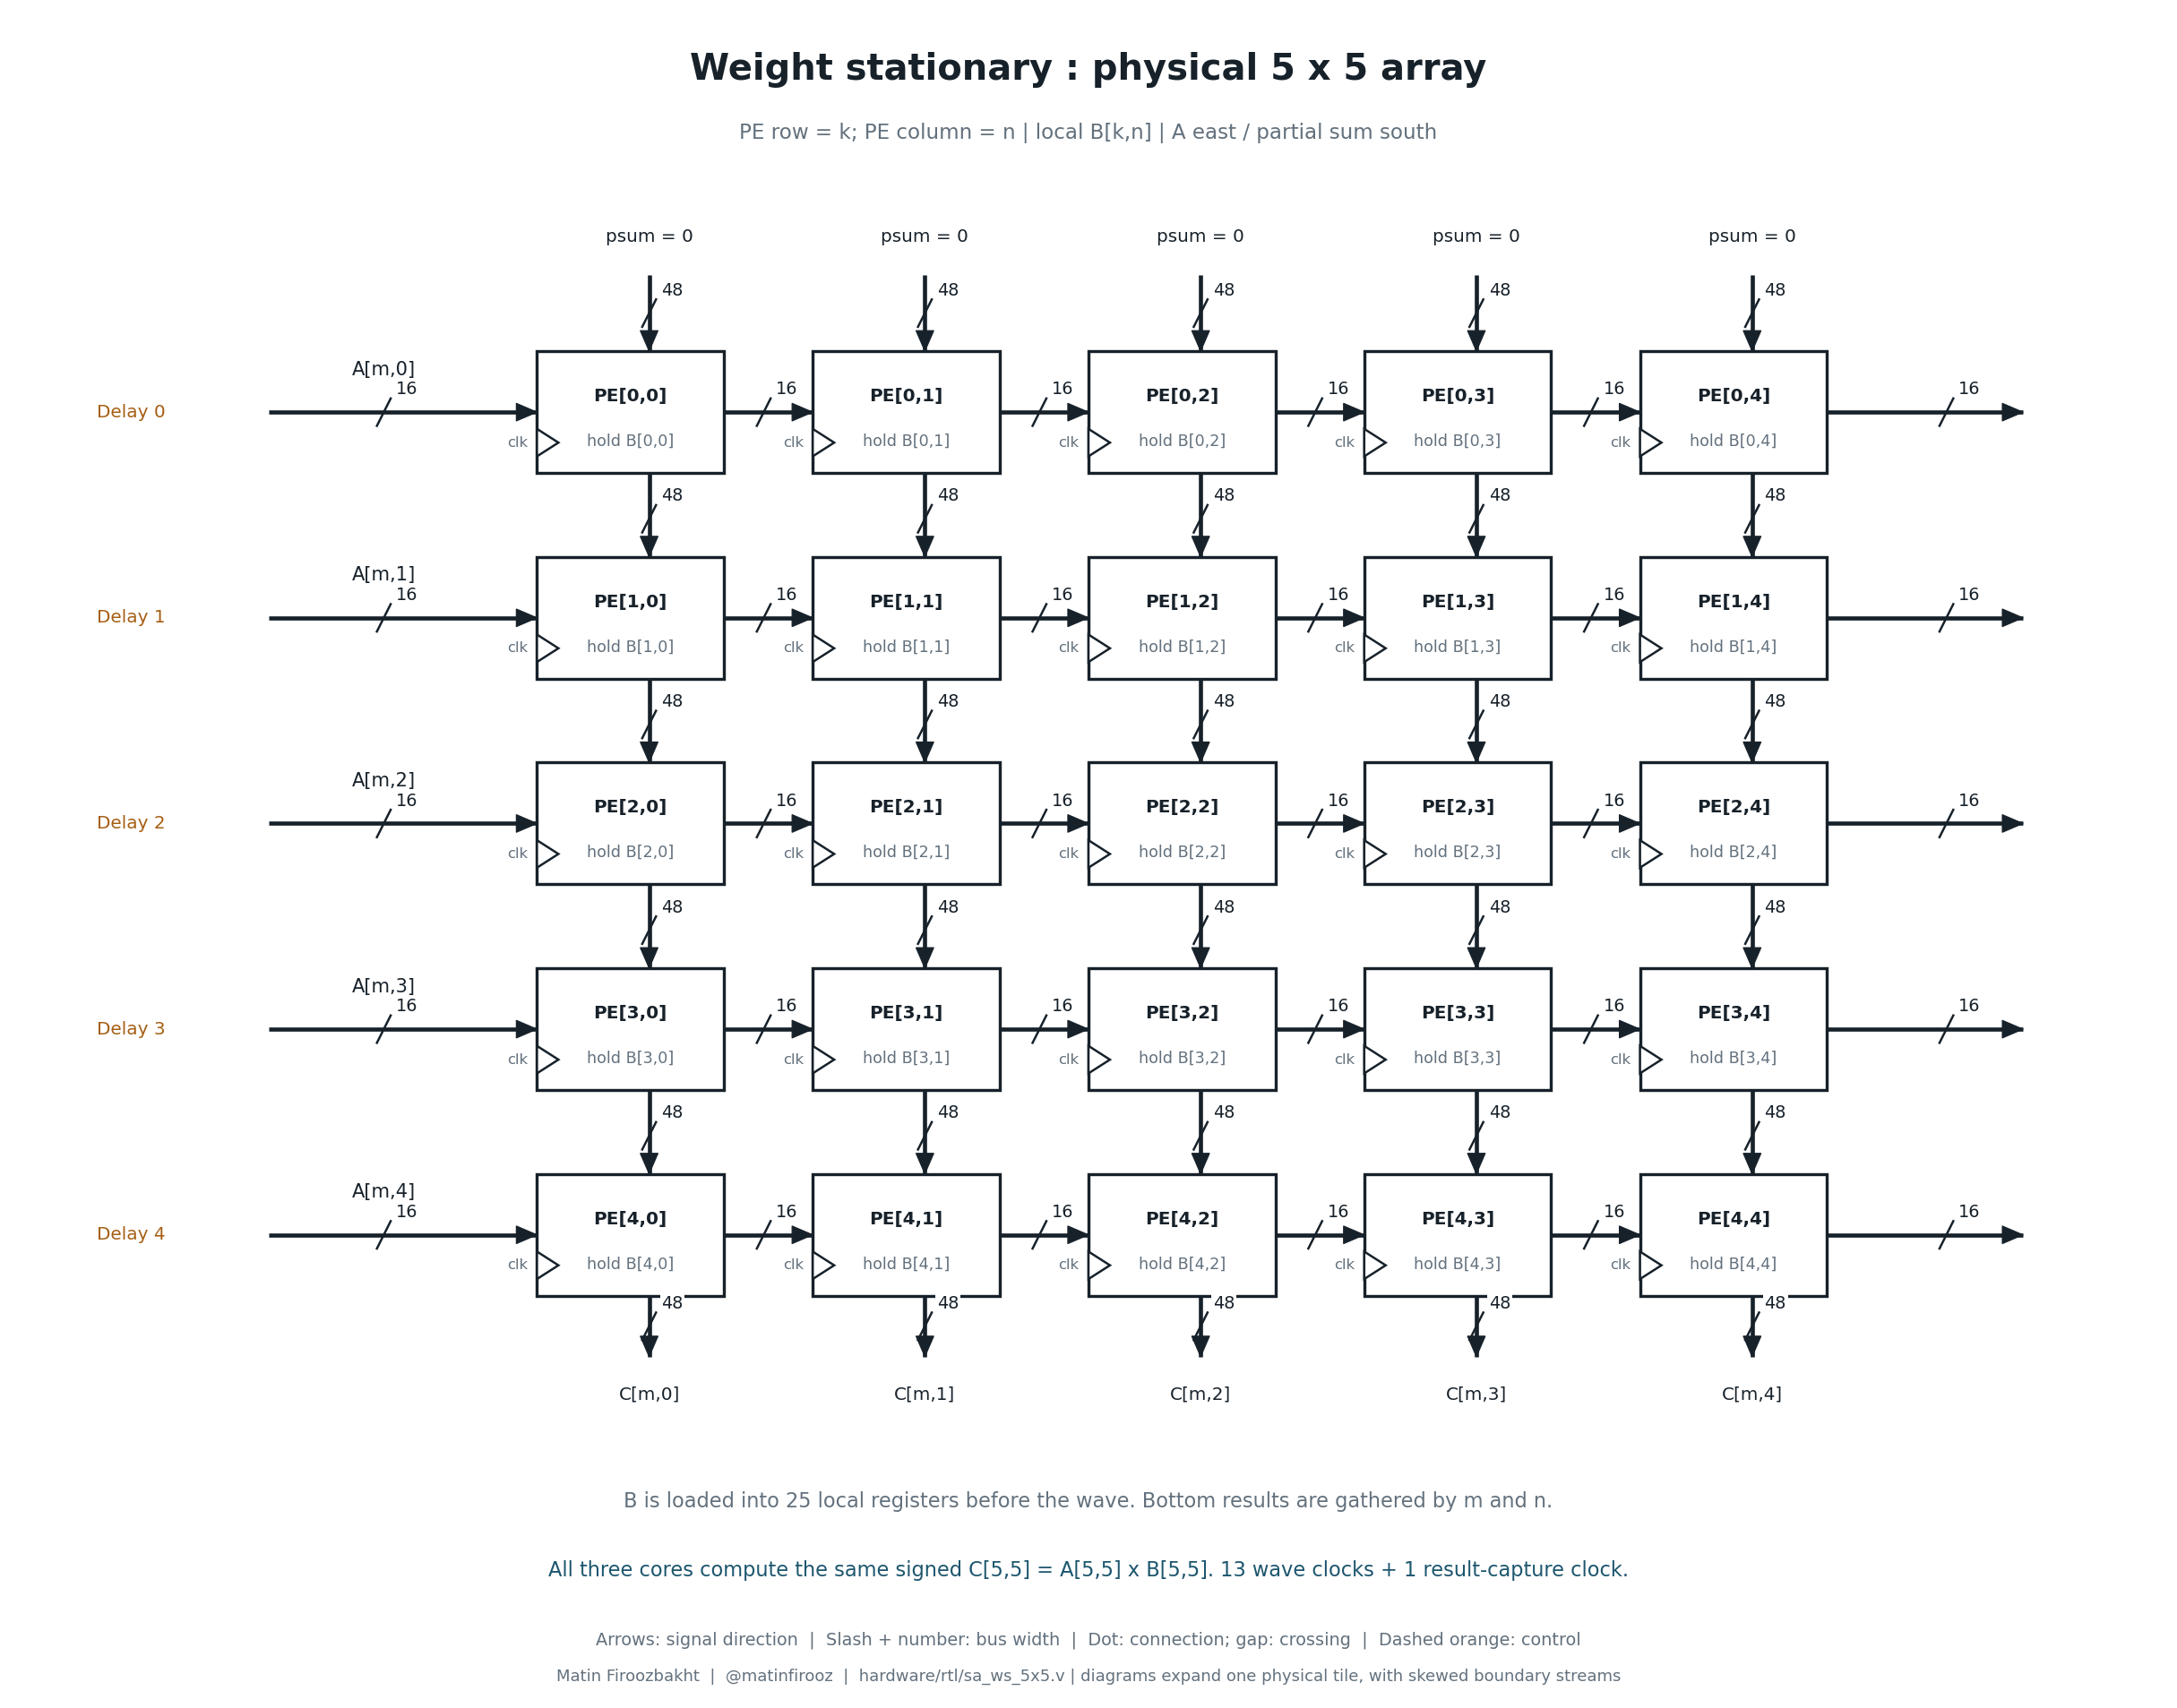

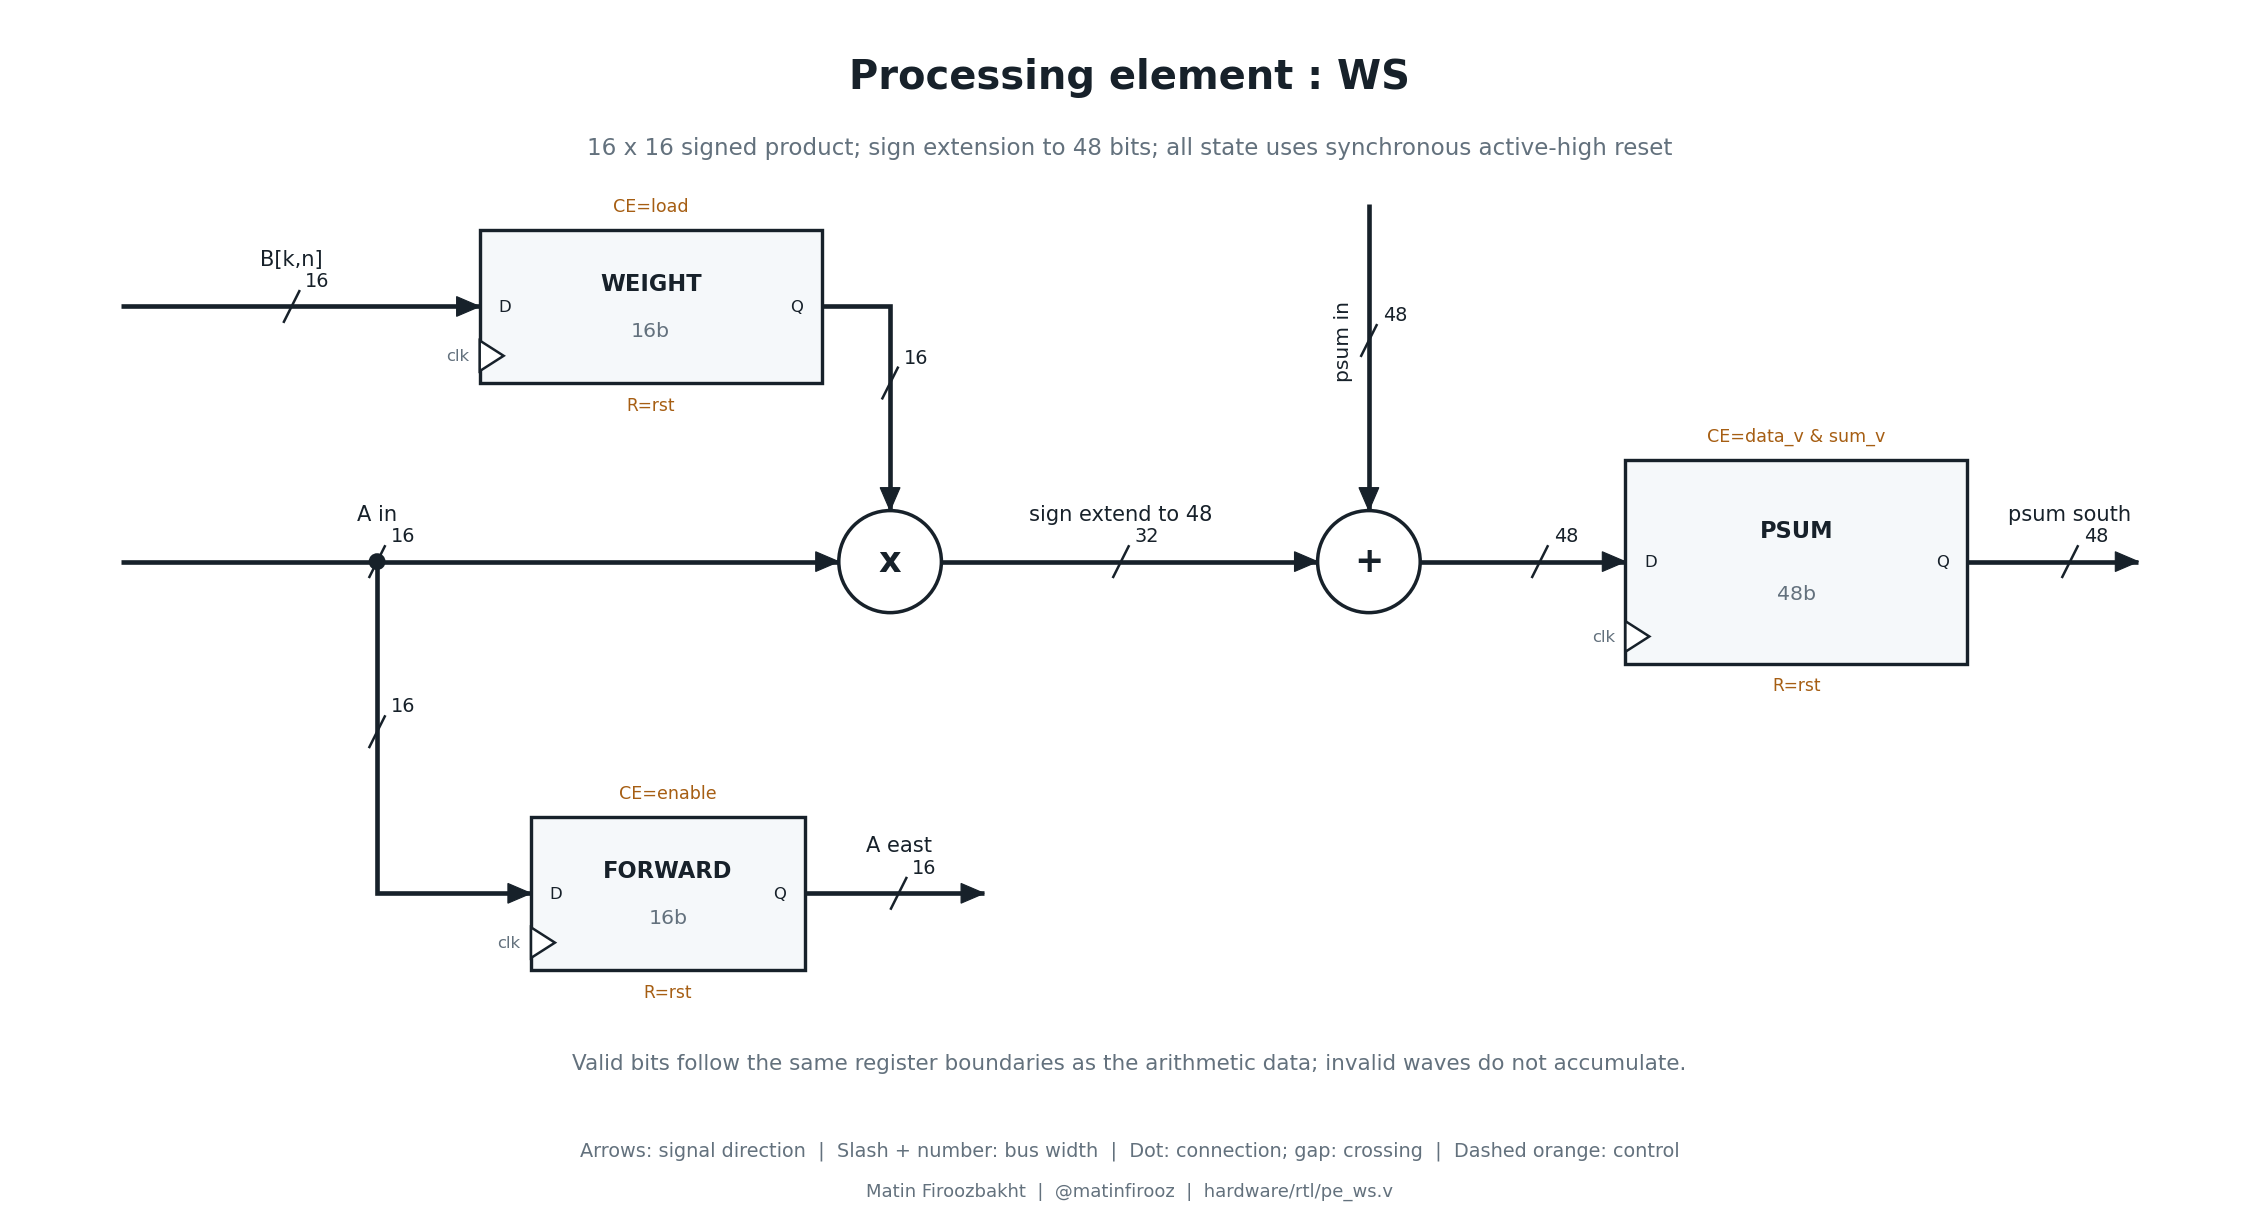

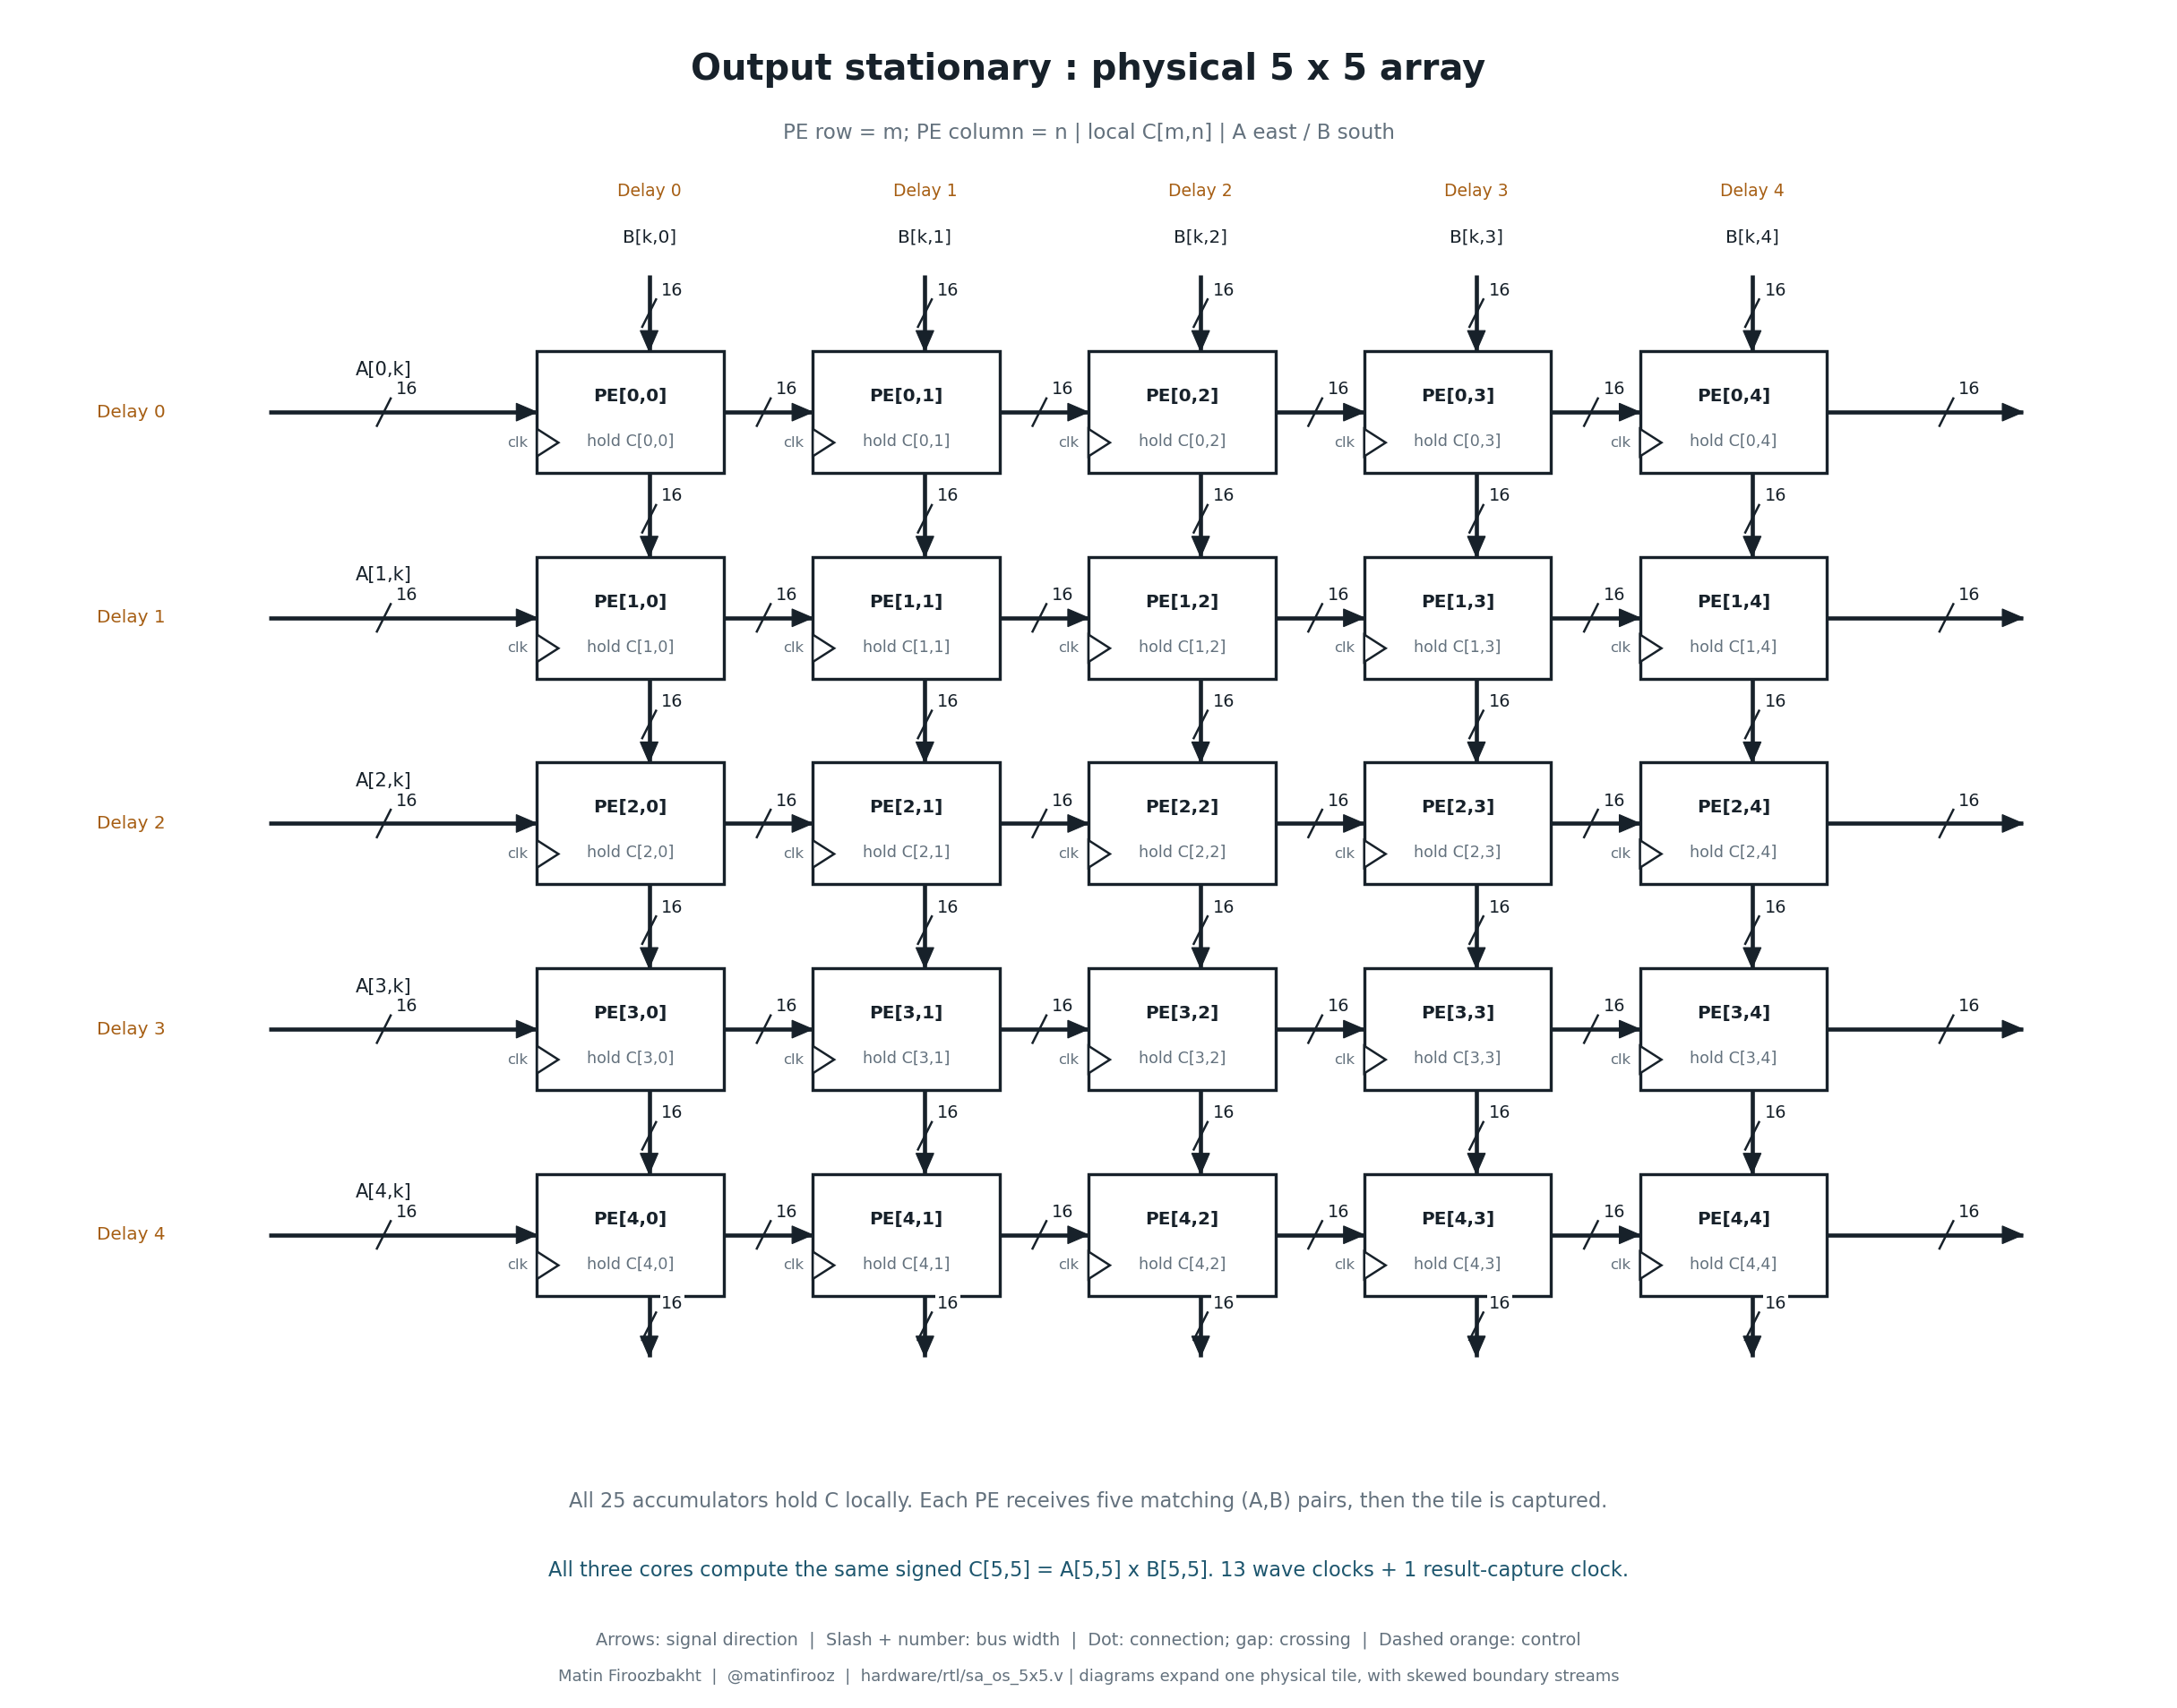

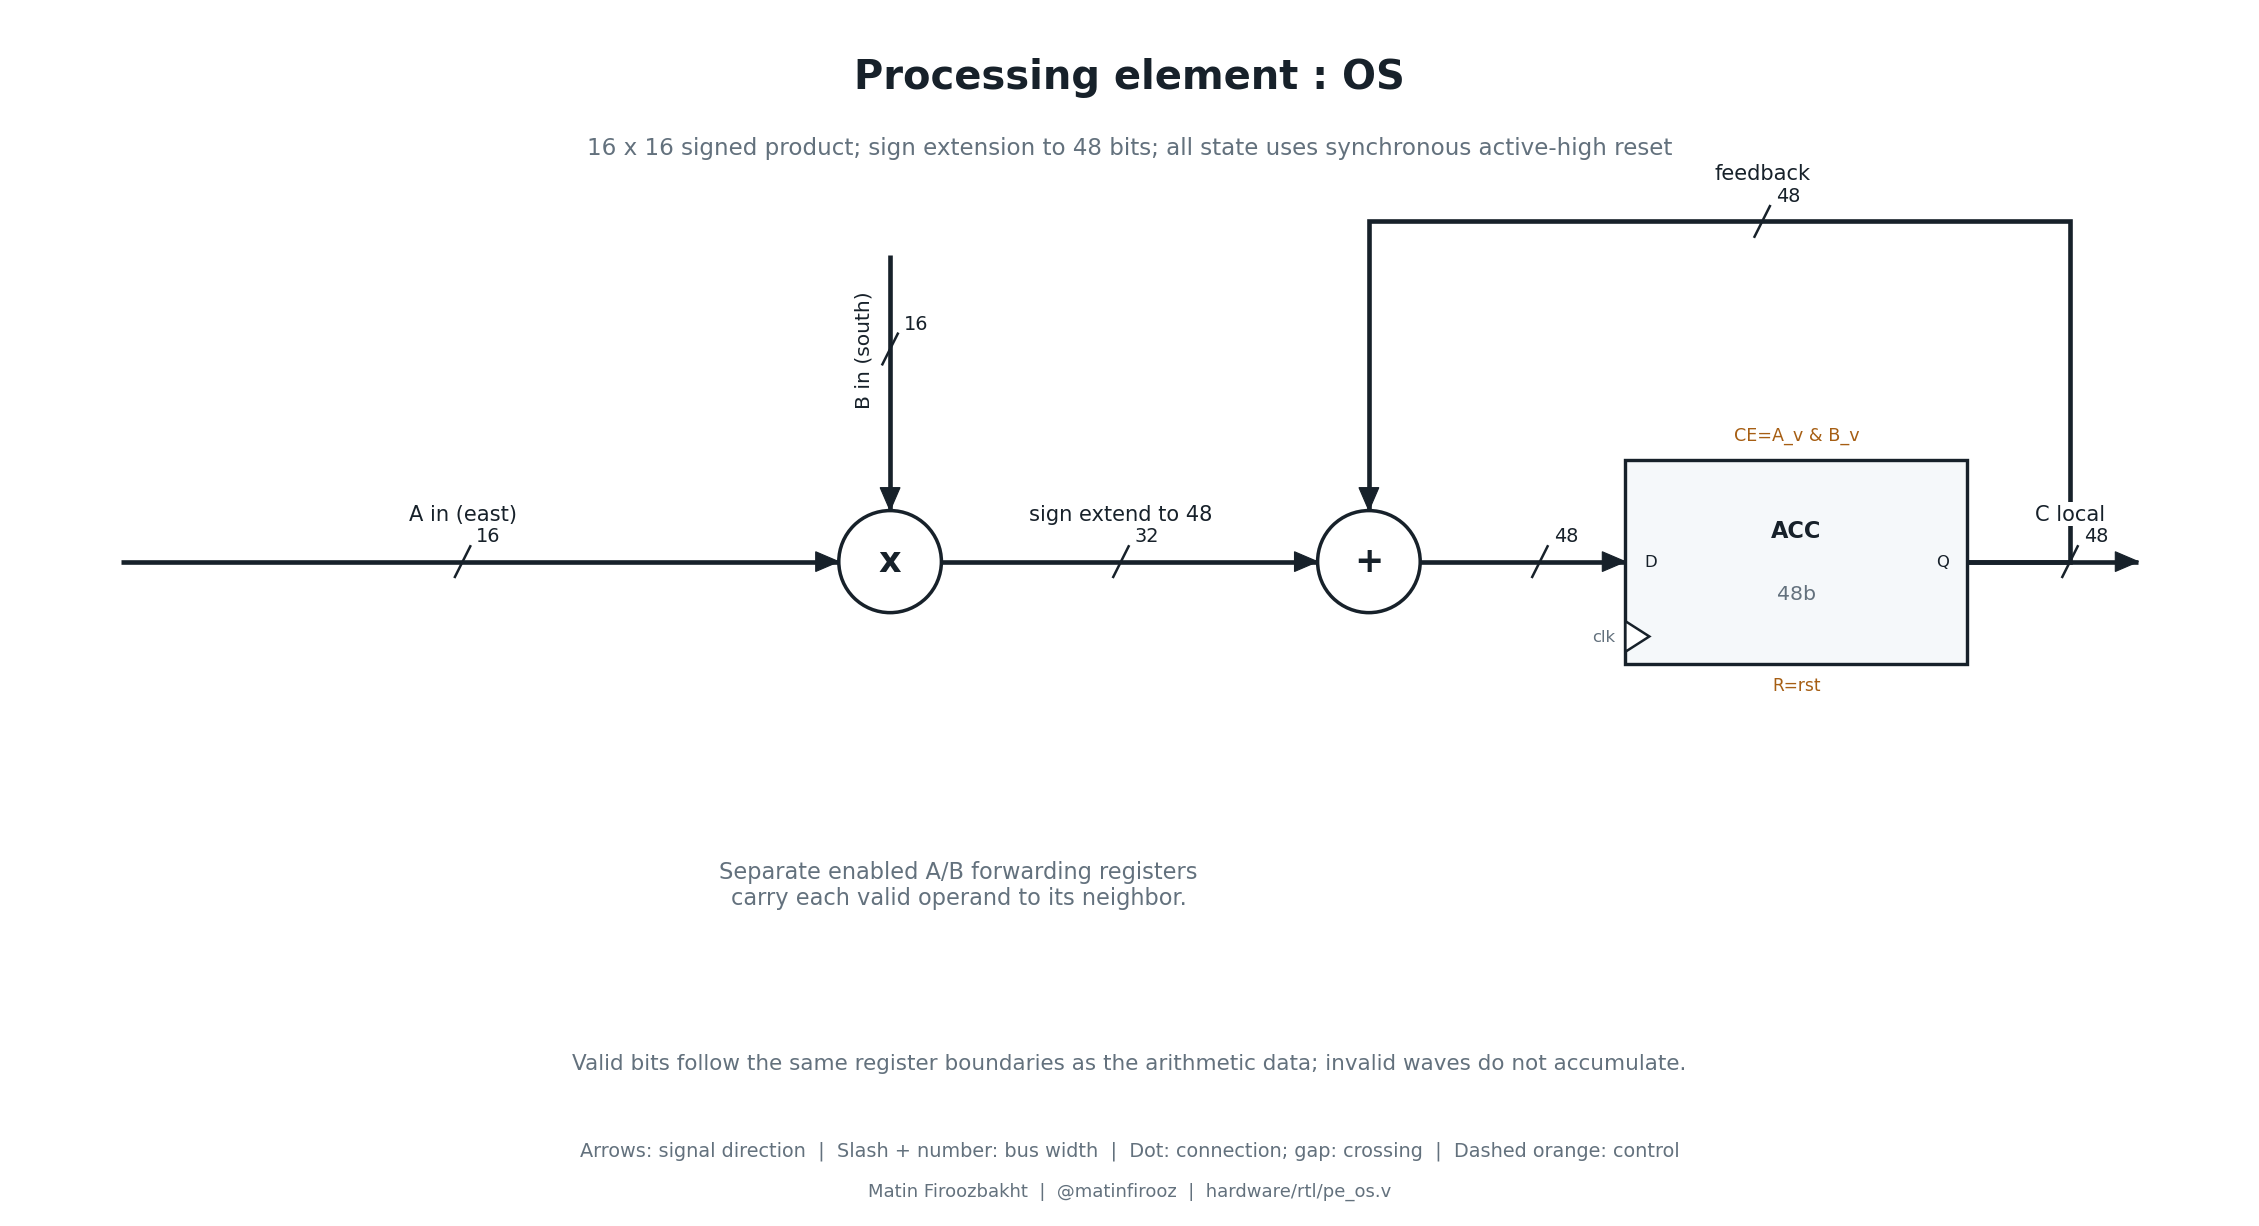

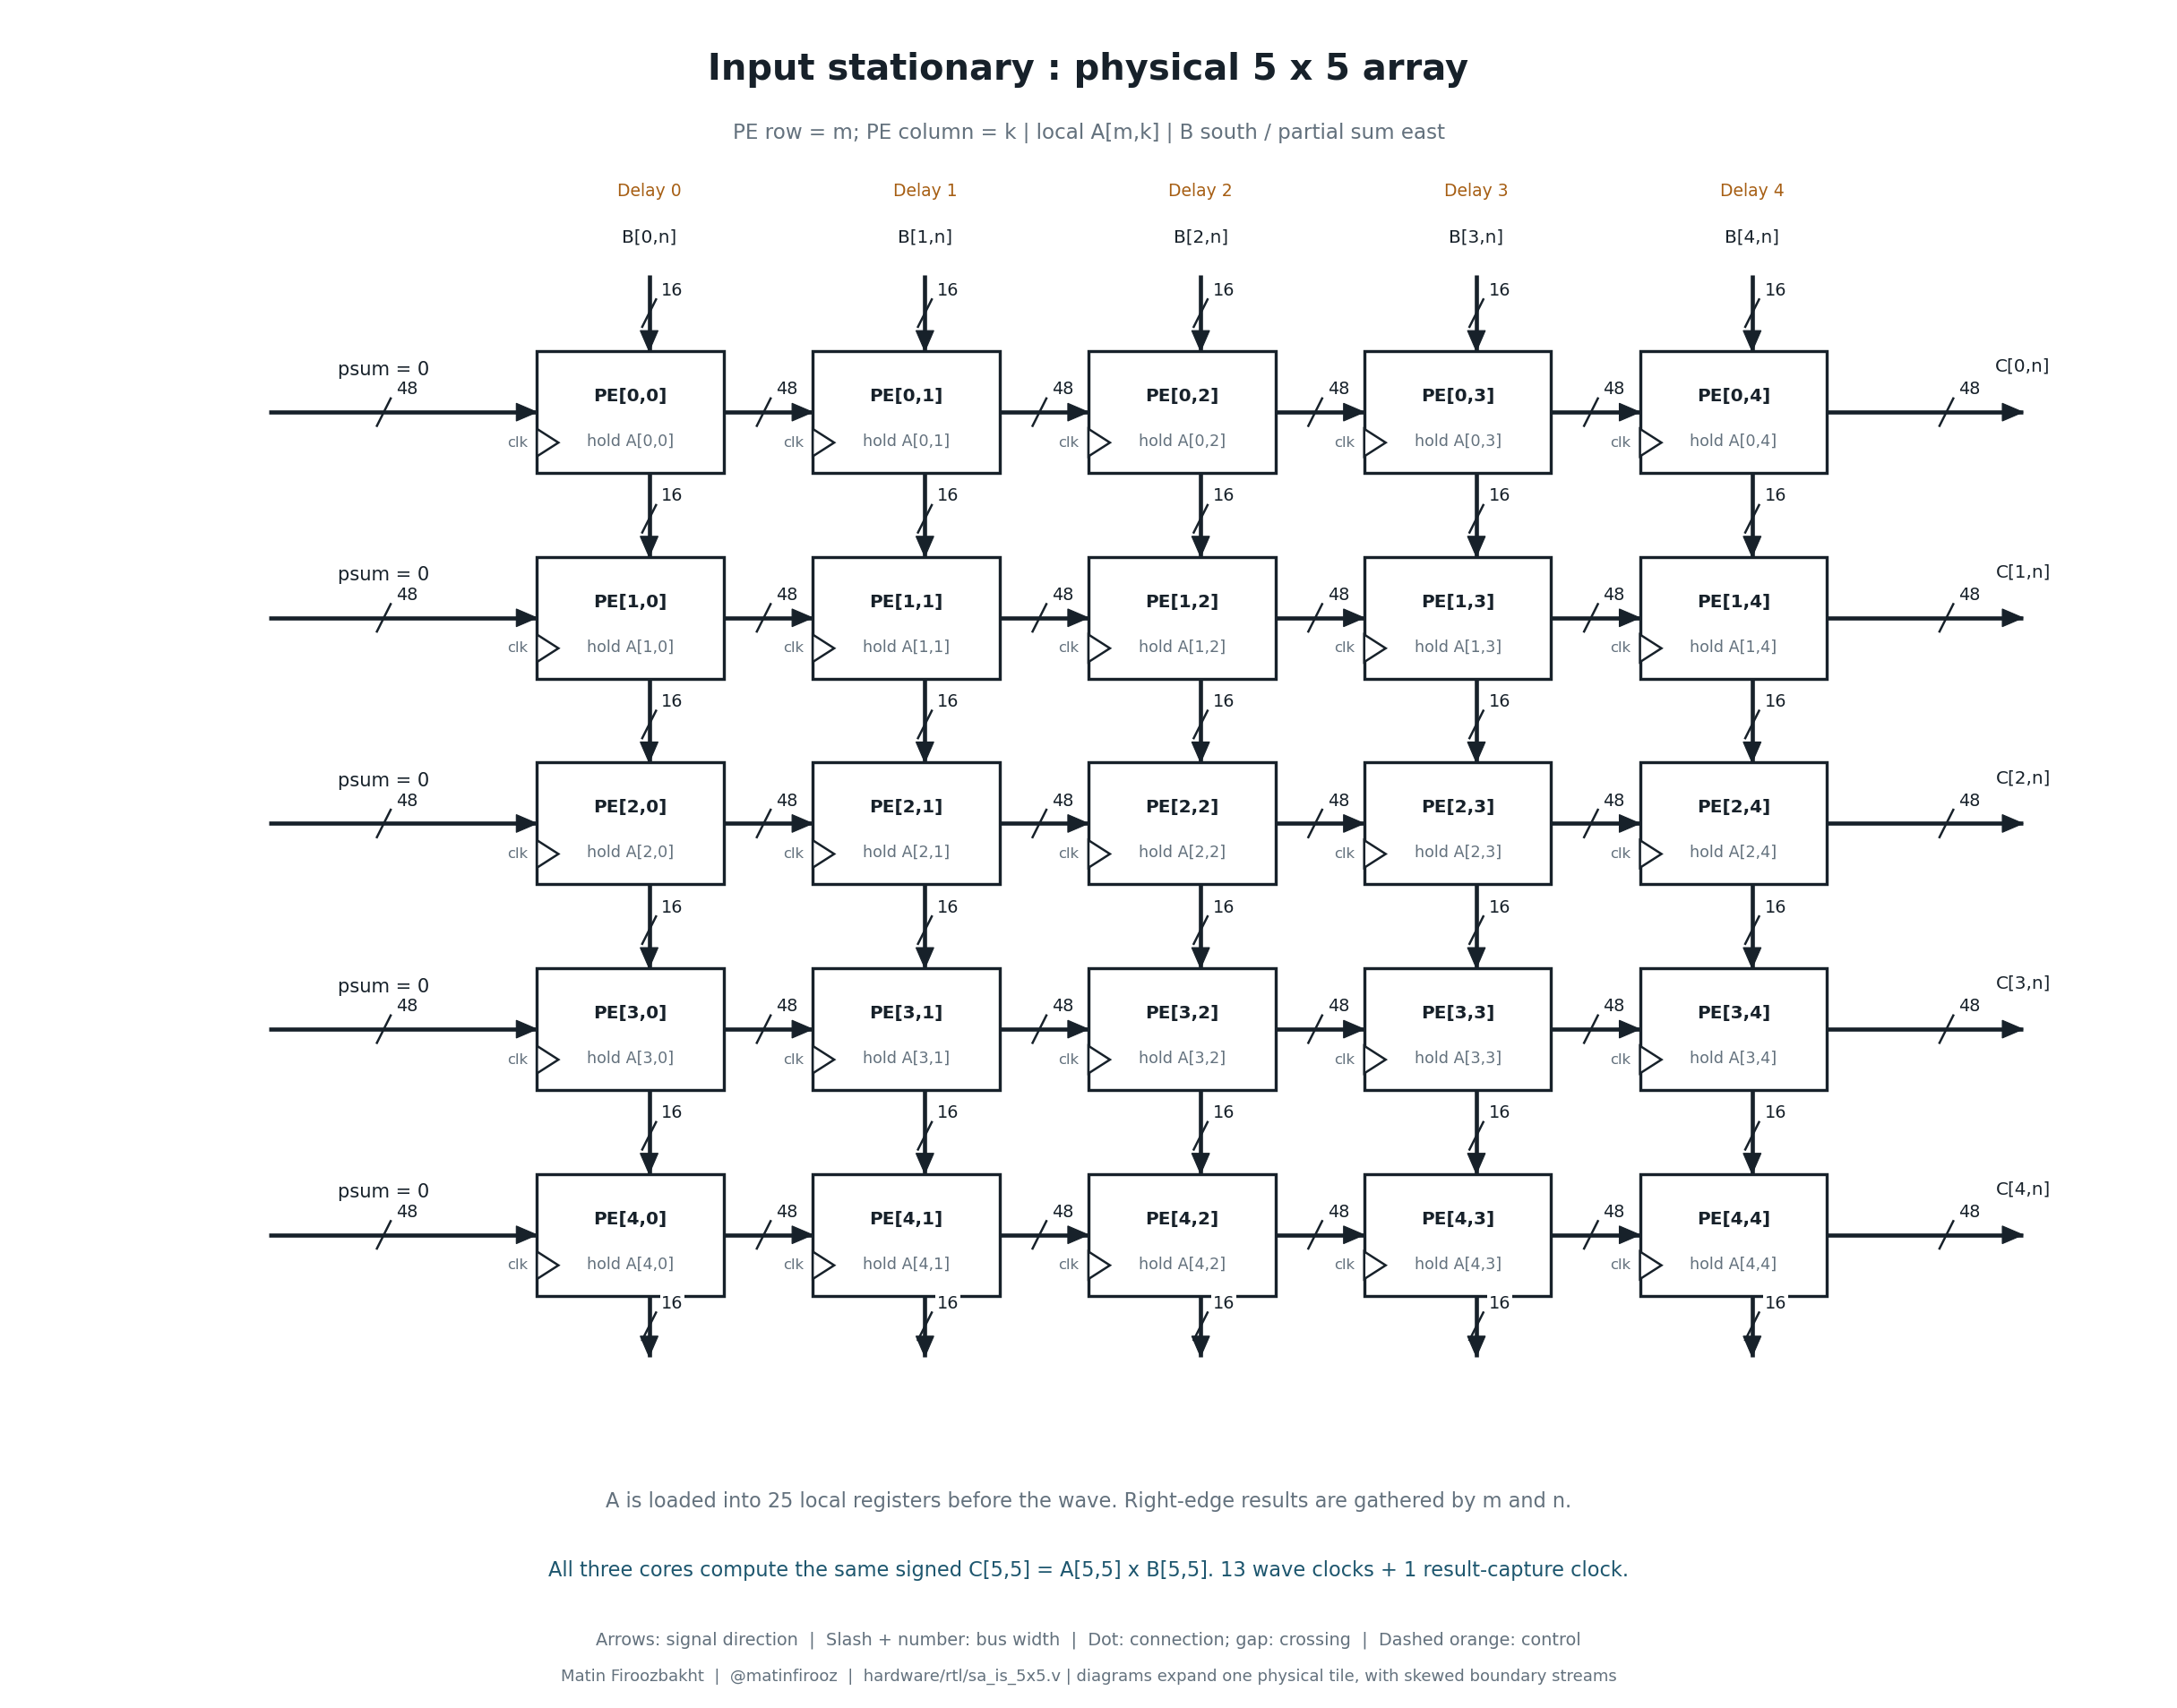

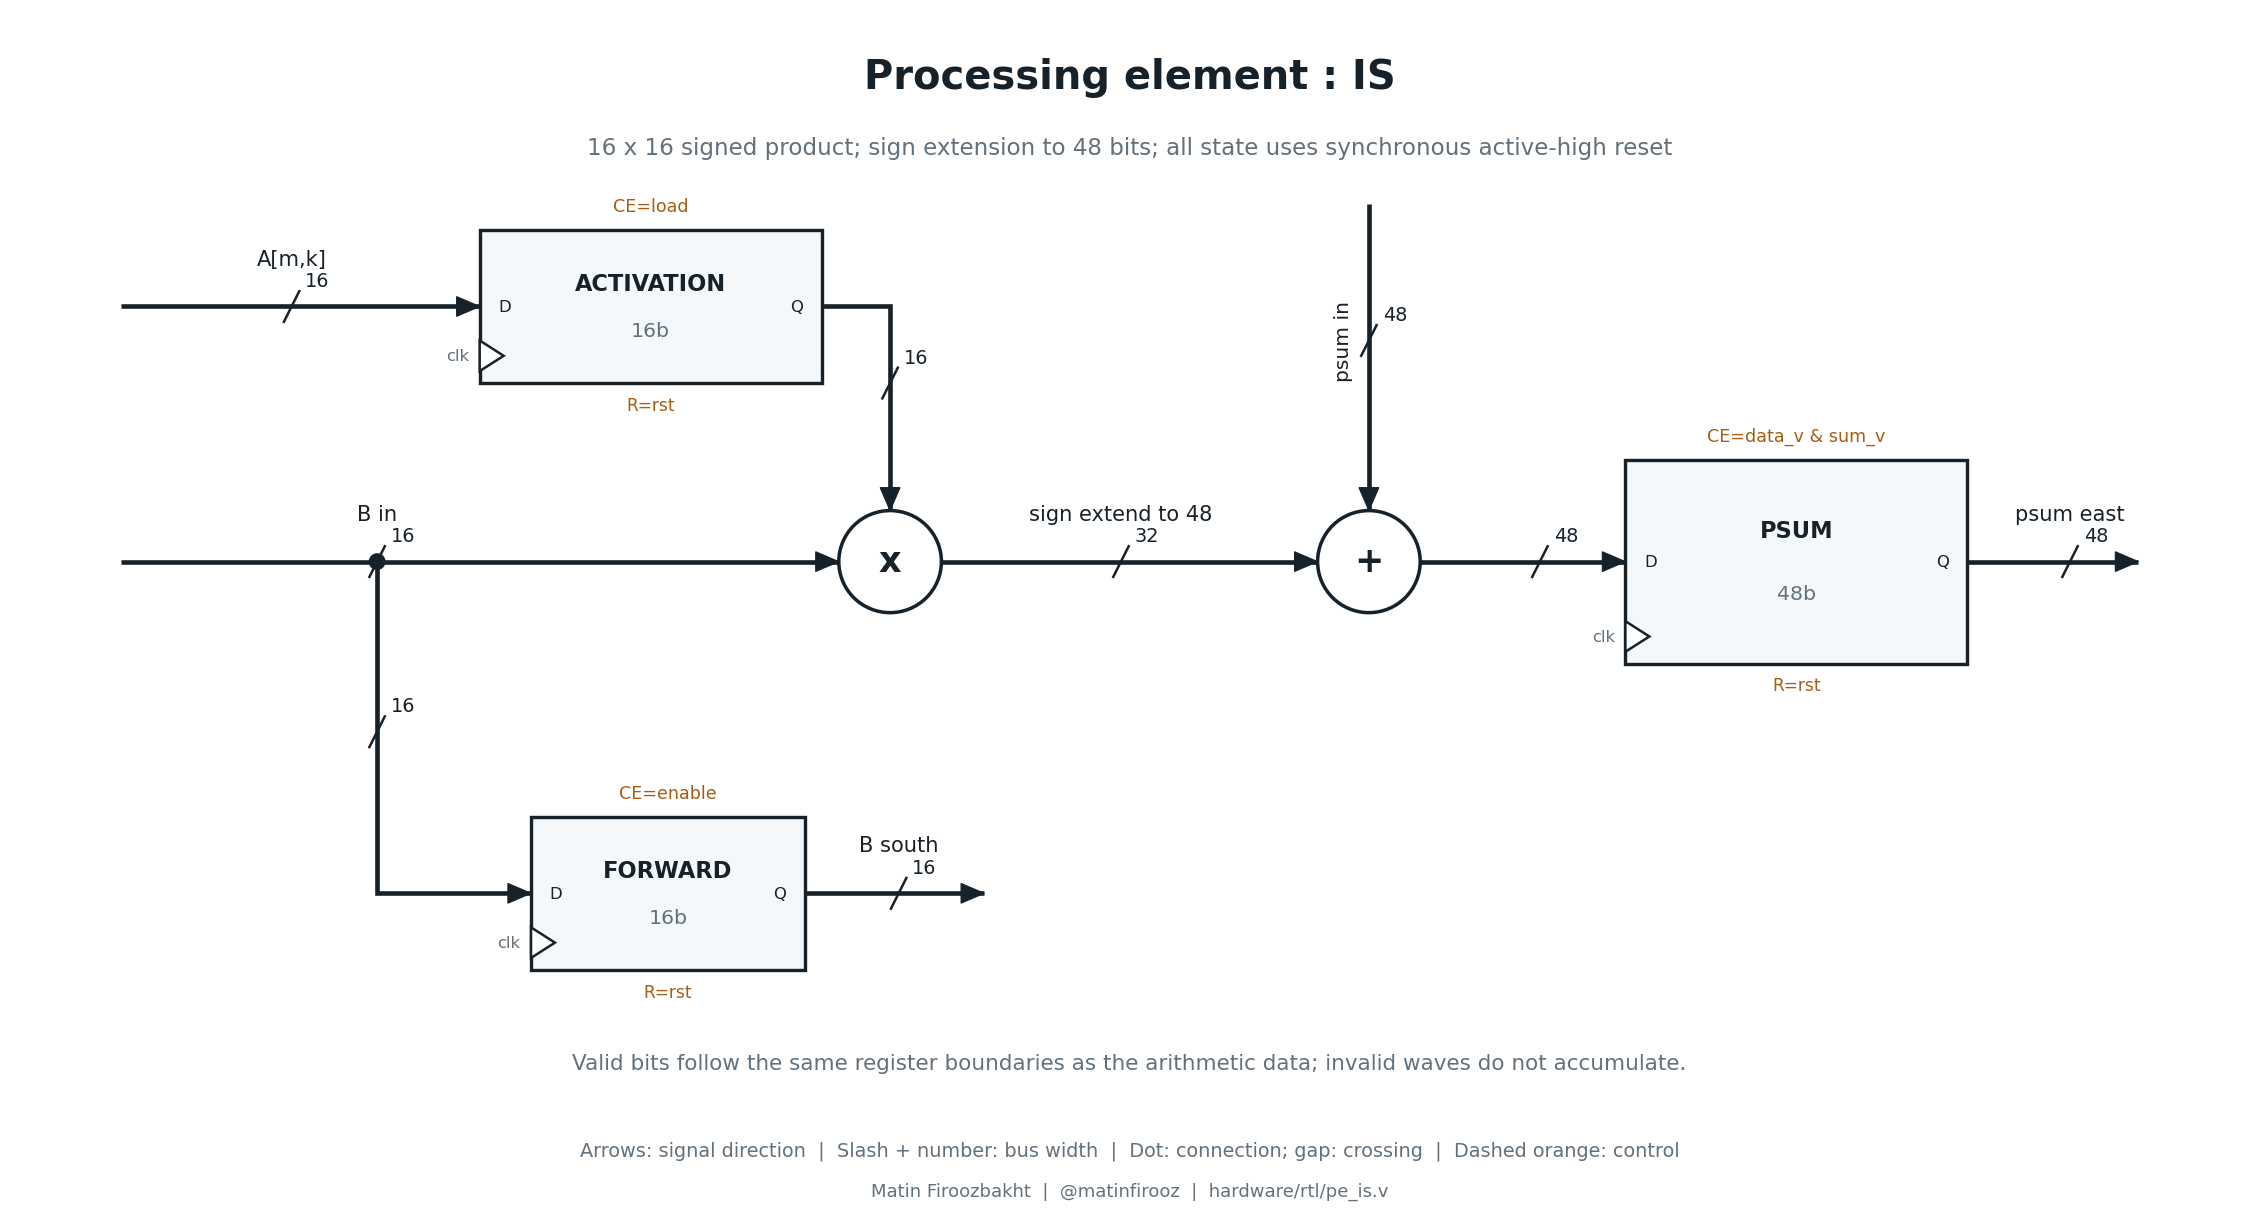

In [5]:
for mode in ['ws','os','is']:
    display(Image(filename=str(ROOT/f'hardware/figures/array_{mode}.png')))
    display(Image(filename=str(ROOT/f'hardware/figures/pe_{mode}.png')))


### Complete HDL source

All 26 source modules are shown below. The top-level controller computes every layer autonomously; the host supplies raw image pixels only.


In [6]:
for path in sorted((ROOT/'hardware/rtl').glob('*.v')):
    display(Markdown('#### '+path.name))
    display(Code(path.read_text(),language='verilog'))


#### activation_memory.v

`timescale 1ns/1ps
module activation_memory(input wire clk,read_enable,read_bank,input wire[12:0]read_address,
 output reg signed[15:0]read_data,input wire write_enable,write_bank,input wire[12:0]write_address,
 input wire signed[15:0]write_data);
 (* ram_style="block" *)reg signed[15:0]bank0[0:8191],bank1[0:8191];
 always @(posedge clk)begin
  if(read_enable)read_data<=read_bank?bank1[read_address]:bank0[read_address];
  if(write_enable)begin if(write_bank)bank1[write_address]<=write_data;else bank0[write_address]<=write_data;end
 end
endmodule

#### argmax_serial.v

`timescale 1ns/1ps
module argmax_serial(input wire clk,rst,clear,valid,input wire[3:0]index,input wire signed[47:0]logit,
 output reg[3:0]best_index,output reg signed[47:0]best_logit);
 reg seen;
 always @(posedge clk)begin
  if(rst||clear)begin seen<=0;best_index<=0;best_logit<=0;end
  else if(valid&&(!seen||logit>best_logit||(logit==best_logit&&index<best_index)))begin
   seen<=1;best_index<=index;best_logit<=logit;
  end
 end
endmodule

#### average_pool.v

`timescale 1ns/1ps
module average_pool(input wire signed[15:0]a,b,c,d,output wire signed[47:0]mean_q24);
 wire signed[17:0]sum=$signed({{2{a[15]}},a})+$signed({{2{b[15]}},b})+$signed({{2{c[15]}},c})+$signed({{2{d[15]}},d});
 assign mean_q24=$signed({{30{sum[17]}},sum})<<<10;
endmodule

... (42 outputs left out)

#### weight_cache.v

`timescale 1ns/1ps
// Exactly 512 x 16 data bits = 1 KiB. 64 direct-mapped lines, eight words/line.
// A hit retires one clock after acceptance. Misses refill from the four-cycle L2.
module weight_cache #(parameter integer DEPTH=61470)(
 input wire clk,rst,req_valid,output wire req_ready,input wire[15:0]req_address,
 output wire resp_valid,input wire resp_ready,output reg[15:0]resp_data,
 output wire l2_req_valid,input wire l2_req_ready,output wire[15:0]l2_req_address,
 input wire l2_resp_valid,output wire l2_resp_ready,input wire[15:0]l2_resp_data,
 output reg[31:0]request_count,hit_count);
 localparam IDLE=0,MISS_REQ=1,MISS_WAIT=2,RESP=3;
 reg[1:0]state;reg[15:0]saved;reg[2:0]offset;reg[15:0]selected;
 (* ram_style="block" *) reg[15:0]data[0:511];
 reg[6:0]tags[0:63];reg[63:0]valid;
 wire[16:0]fill_address={1'b0,saved[15:3],3'b000}+offset;
 wire[16:0]next_fill_address=fill_address+17'd1;
 wire chain_read=(state==MISS_WAIT)&&l2_resp_valid&&(offset<7)&&(next_fill_address<DEPTH);
 assign req_ready=(state==IDLE);assign resp_valid=(state==RESP);
 // Retire one L2 word and launch the next on the same edge: four-clock refill II.
 assign l2_req_valid=((state==MISS_REQ)&&(fill_address<DEPTH))||chain_read;
 assign l2_req_address=chain_read?next_fill_address[15:0]:fill_address[15:0];
 assign l2_resp_ready=(state==MISS_WAIT);
 integer i;
 always @(posedge clk)begin
  if(rst)begin state<=IDLE;saved<=0;offset<=0;selected<=0;valid<=0;resp_data<=0;request_count<=0;hit_count<=0;for(i=0;i<64;i=i+1)tags[i]<=0;end
  else case(state)
   IDLE:if(req_valid)begin
    saved<=req_address;request_count<=request_count+1'b1;
    if(valid[req_address[8:3]]&&tags[req_address[8:3]]==req_address[15:9])begin
     resp_data<=data[req_address[8:0]];hit_count<=hit_count+1'b1;state<=RESP;
    end else begin offset<=0;selected<=0;state<=MISS_REQ;end
   end
   MISS_REQ:begin
    if(fill_address>=DEPTH)begin
     data[{saved[8:3],offset}]<=0;
     if(offset==7)begin valid[saved[8:3]]<=1;tags[saved[8:3]]<=saved[15:9];resp_data<=selected;state<=RESP;end
     else offset<=offset+1'b1;
    end else if(l2_req_ready)state<=MISS_WAIT;
   end
   MISS_WAIT:if(l2_resp_valid)begin
    data[{saved[8:3],offset}]<=l2_resp_data;
    if(offset==saved[2:0])selected<=l2_resp_data;
    if(offset==7)begin
     valid[saved[8:3]]<=1;tags[saved[8:3]]<=saved[15:9];resp_data<=(saved[2:0]==7)?l2_resp_data:selected;state<=RESP;
    end else begin offset<=offset+1'b1;state<=(chain_read&&l2_req_ready)?MISS_WAIT:MISS_REQ;end
   end
   RESP:if(resp_ready)state<=IDLE;
   default:state<=IDLE;
  endcase
 end
endmodule

#### weight_memory.v

`timescale 1ns/1ps
module weight_memory #(parameter integer CACHE_ENABLE=0,parameter INIT_FILE="hardware/mem/weights.hex")(
 input wire clk,rst,req_valid,output wire req_ready,input wire[15:0]req_address,
 output wire resp_valid,input wire resp_ready,output wire[15:0]resp_data,
 output wire[31:0]request_count,hit_count,l2_reads);
 wire dv,dr,rv,rr;wire[15:0]da,rd;
 dram_model #(.LATENCY(4),.INIT_FILE(INIT_FILE))u_dram(clk,rst,dv,dr,da,rv,rr,rd,l2_reads);
 generate if(CACHE_ENABLE)begin:CACHED
  weight_cache u_cache(clk,rst,req_valid,req_ready,req_address,resp_valid,resp_ready,resp_data,
   dv,dr,da,rv,rr,rd,request_count,hit_count);
 end else begin:DIRECT
  assign dv=req_valid;assign req_ready=dr;assign da=req_address;assign resp_valid=rv;
  assign rr=resp_ready;assign resp_data=rd;assign request_count=l2_reads;assign hit_count=32'd0;
 end endgenerate
endmodule

## 5. Numeric formats and nonlinear operations

| Quantity | Representation | Interpretation |
| --- | --- | --- |
| Raw pixel | u8 | Integer 0..255 |
| Normalized input | signed 16-bit Q12 | floor((pixel*4096+127)/255) |
| Weight / tanh output | signed 16-bit Q12 | Integer / 4096 |
| Raw product | signed 32-bit Q24 | Sign-extended before addition |
| Bias / accumulator / logit | signed 48-bit Q24 | Integer / 16777216 |
| Probability | unsigned 16-bit Q16 | Integer / 65536 |

Weights round with floor(real*4096+0.5); biases use floor(real*2^24+0.5).
The export has 0 clipped weights/biases. For every output neuron,
abs(bias) + 4096*sum(abs(weights)) bounds its accumulator because normalized inputs
and all tanh activations have magnitude at most 4096. Every recorded bound is below
2^47, so 48-bit accumulation is safe over the entire stated input domain.

The tanh ROM has 4,097 Q12 words for inputs -8..8 on a 1/256 grid. Its address is
clamp((sign_extend_49(acc)+32768) arithmetic_shift_right 16, -2048, 2048)+2048.
Widening precedes rounding, including at signed 48-bit extremes. Average pooling
sums four sign-extended Q12 words and shifts that sum left by 10 to represent the
exact mean in Q24 before the same tanh lookup; no intermediate divide rounding occurs.

Softmax first finds the signed maximum and deterministic argmax. A 4,097-entry
Q24 exponential ROM approximates exp(-delta), delta in [0,16] on a 1/256 grid.
Maximum subtraction is widened to 50 bits before rounding. Ten exp values sum in
32 bits. A sixteen-step restoring divider emits floor((exp*65536)/denominator).
The integer probabilities sum to at most 65,536 and lose fewer than ten integer
units to final division truncation; lookup approximation adds its own error relative
to real softmax. Predictions use the full logits, so probability quantization does
not manufacture class ties.


,layer,maximum_accumulator_bound,fits_signed_48
0,conv1,111712280,True
1,conv3,339174427,True
2,conv5,516119415,True
3,fc6,226884753,True
4,fc7,285131418,True


,tensor,clips
0,conv1.weight,0
1,conv1.bias,0
2,conv3.weight,0
3,conv3.bias,0
4,conv5.weight,0
5,conv5.bias,0
6,fc6.weight,0
7,fc6.bias,0
8,fc7.weight,0
9,fc7.bias,0


"""Bit-exact Q12 activations/weights and Q24 48-bit accumulators."""
from pathlib import Path
import numpy as np

LAYERS=[('conv1',1,32,6,28,25,0,0),('conv3',6,14,16,10,150,150,6),
        ('conv5',16,5,120,1,400,2550,22),('fc6',120,1,84,1,120,50550,142),('fc7',84,1,10,1,84,60630,226)]
TRACE_OFFSETS=[0,4704,5880,7480,7880,8000]
TRACE_WORDS=8084

def quantize(weights):
    result={};clips={}
    for name,value in weights.items():
        scale=1<<24 if name.endswith('bias') else 1<<12
        v=np.floor(value.astype(np.float64)*scale+.5).astype(np.int64)
        low,high=(-(1<<47),(1<<47)-1) if name.endswith('bias') else (-32768,32767)
        clips[name]=int(np.count_nonzero((v<low)|(v>high)))
        result[name]=np.clip(v,low,high)
    result['tanh_lut']=np.floor(np.tanh(np.arange(-2048,2049,dtype=np.float64)/256)*4096+.5).astype(np.int64)
    result['exp_lut']=np.floor(np.exp(-np.arange(4097,dtype=np.float64)/256)*(1<<24)+.5).astype(np.int64)
    return result,clips

def tanh_acc(acc,lut):
    address=np.clip((acc+32768)>>16,-2048,2048)+2048
    return lut[address]

def conv_integer(x,w,b,lut):
    bs,cin,iw,_=x.shape;cout=w.shape[0];ow=iw-4
    patches=np.lib.stride_tricks.sliding_window_view(x,(5,5),axis=(2,3))
    a=np.ascontiguousarray(patches.transpose(0,2,3,1,4,5).reshape(-1,cin*25))
    acc=a@w.reshape(cout,-1).T+b
    return tanh_acc(acc,lut).reshape(bs,ow,ow,cout).transpose(0,3,1,2).copy()

def pool_integer(x,lut):
    total=x[:,:,0::2,0::2]+x[:,:,0::2,1::2]+x[:,:,1::2,0::2]+x[:,:,1::2,1::2]
    return tanh_acc(total<<10,lut)

def infer_integer(raw,q,trace=False):
    x=np.pad((raw.astype(np.int64)*4096+127)//255,((0,0),(2,2),(2,2)))[:,None,:,:]
    values=[];lut=q['tanh_lut']
    x=conv_integer(x,q['conv1.weight'],q['conv1.bias'],lut);values.append(x)
    x=pool_integer(x,lut);values.append(x)
    x=conv_integer(x,q['conv3.weight'],q['conv3.bias'],lut);values.append(x)
    x=pool_integer(x,lut);values.append(x)
    x=conv_integer(x,q['conv5.weight'],q['conv5.bias'],lut).reshape(len(raw),120);values.append(x)
    x=tanh_acc(x@q['fc6.weight'].T+q['fc6.bias'],lut);values.append(x)
    logits=x@q['fc7.weight'].T+q['fc7.bias']
    address=np.clip((logits.max(1,keepdims=True)-logits+32768)>>16,0,4096)
    exps=q['exp_lut'][address];probabilities=np.minimum(65535,(exps<<16)//exps.sum(1,keepdims=True))
    result={'logits':logits,'probabilities':probabilities,'predictions':logits.argmax(1)}
    if trace:result['trace']=np.concatenate([v.reshape(len(raw),-1) for v in values],axis=1)
    return result

def write_hex(path,values,width):
    mask=(1<<width)-1
    Path(path).write_text(''.join(f'{int(v)&mask:0{width//4}x}\n' for v in np.asarray(values).reshape(-1)))

"""Export every trained parameter and evaluate the integer network on 10,000 test images."""
import argparse,csv,hashlib,json,sys
from pathlib import Path
from time import perf_counter
ROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT))
import numpy as np
from software.data import load_idx
from software.fixed_point import quantize,infer_integer,write_hex,LAYERS

def main():
    p=argparse.ArgumentParser();p.add_argument('--rtl-images',type=int,default=16);args=p.parse_args()
    weights=dict(np.load(ROOT/'software/trained_weights.npz'));q,clips=quantize(weights)
    np.savez_compressed(ROOT/'software/integer_weights.npz',**q)
    allw=np.concatenate([q[name+'.weight'].reshape(-1) for name,*_ in LAYERS]);allb=np.concatenate([q[name+'.bias'] for name,*_ in LAYERS])
    assert len(allw)==61470 and len(allb)==236
    mem=ROOT/'hardware/mem';write_hex(mem/'weights.hex',allw,16);write_hex(mem/'biases.hex',allb,48)
    write_hex(mem/'tanh.hex',q['tanh_lut'],16);write_hex(mem/'exp.hex',q['exp_lut'],32)
    with (ROOT/'results/software/parameters.csv').open('w',newline='') as stream:
        writer=csv.writer(stream);writer.writerow(['tensor','index','floating_value','integer_value','fractional_bits','memory_address'])
        wb=bb=0
        for name,*_ in LAYERS:
            for suffix,frac in [('weight',12),('bias',24)]:
                key=name+'.'+suffix;base=wb if frac==12 else bb
                for i,(f,v) in enumerate(zip(weights[key].reshape(-1),q[key].reshape(-1))):writer.writerow([key,i,format(float(f),'.9g'),int(v),frac,base+i])
                if frac==12:wb+=q[key].size
                else:bb+=q[key].size
    raw,labels=load_idx(ROOT/'data/fashion','t10k');saved=np.load(ROOT/'results/software/float_test_outputs.npz')
    results=[];started=perf_counter()
    for begin in range(0,len(raw),64):
        out=infer_integer(raw[begin:begin+64],q);results.append(out)
        if begin%1024==0:print('Integer evaluation',begin,'/',len(raw),flush=True)
    merged={key:np.concatenate([x[key] for x in results]) for key in results[0]}
    elapsed=perf_counter()-started;pred=merged['predictions'];float_pred=saved['predictions']
    correct=int(np.count_nonzero(pred==labels));disagreements=int(np.count_nonzero(pred!=float_pred))
    np.savez_compressed(ROOT/'results/software/integer_test_outputs.npz',**merged,labels=labels)
    n=min(args.rtl_images,len(raw));reference=infer_integer(raw[:n],q,True)
    per_image=mem/'reference';per_image.mkdir(exist_ok=True)
    for i in range(n):
        write_hex(per_image/f'trace_{i:05d}.hex',reference['trace'][i],16)
        write_hex(per_image/f'logits_{i:05d}.hex',reference['logits'][i],48)
        write_hex(per_image/f'probabilities_{i:05d}.hex',reference['probabilities'][i],16)
    write_hex(mem/'reference_trace.hex',reference['trace'],16);write_hex(mem/'reference_logits.hex',reference['logits'],48)
    write_hex(mem/'reference_probabilities.hex',reference['probabilities'],16);write_hex(mem/'reference_predictions.hex',reference['predictions'],8)
    write_hex(mem/'test_indices.hex',np.arange(n),32)
    with (ROOT/'results/software/test_predictions.csv').open('w',newline='') as f:
        wr=csv.writer(f);wr.writerow(['test_index','label','floating_prediction','integer_prediction','integer_correct'])
        wr.writerows(zip(range(len(raw)),labels.astype(int),float_pred.astype(int),pred.astype(int),(pred==labels).astype(int)))
    bounds=[]
    for name,*_ in LAYERS:
        bound=np.abs(q[name+'.weight']).reshape(q[name+'.weight'].shape[0],-1).sum(1)*4096+np.abs(q[name+'.bias'])
        assert np.all(bound<(1<<47));bounds.append({'layer':name,'maximum_accumulator_bound':int(bound.max()),'fits_signed_48':True})
    result={'status':'completed','n_test':len(labels),'correct':correct,'accuracy':correct/len(labels),'floating_correct':int(np.count_nonzero(float_pred==labels)),'floating_integer_disagreements':disagreements,'prediction_agreement':1-disagreements/len(labels),'weight_b

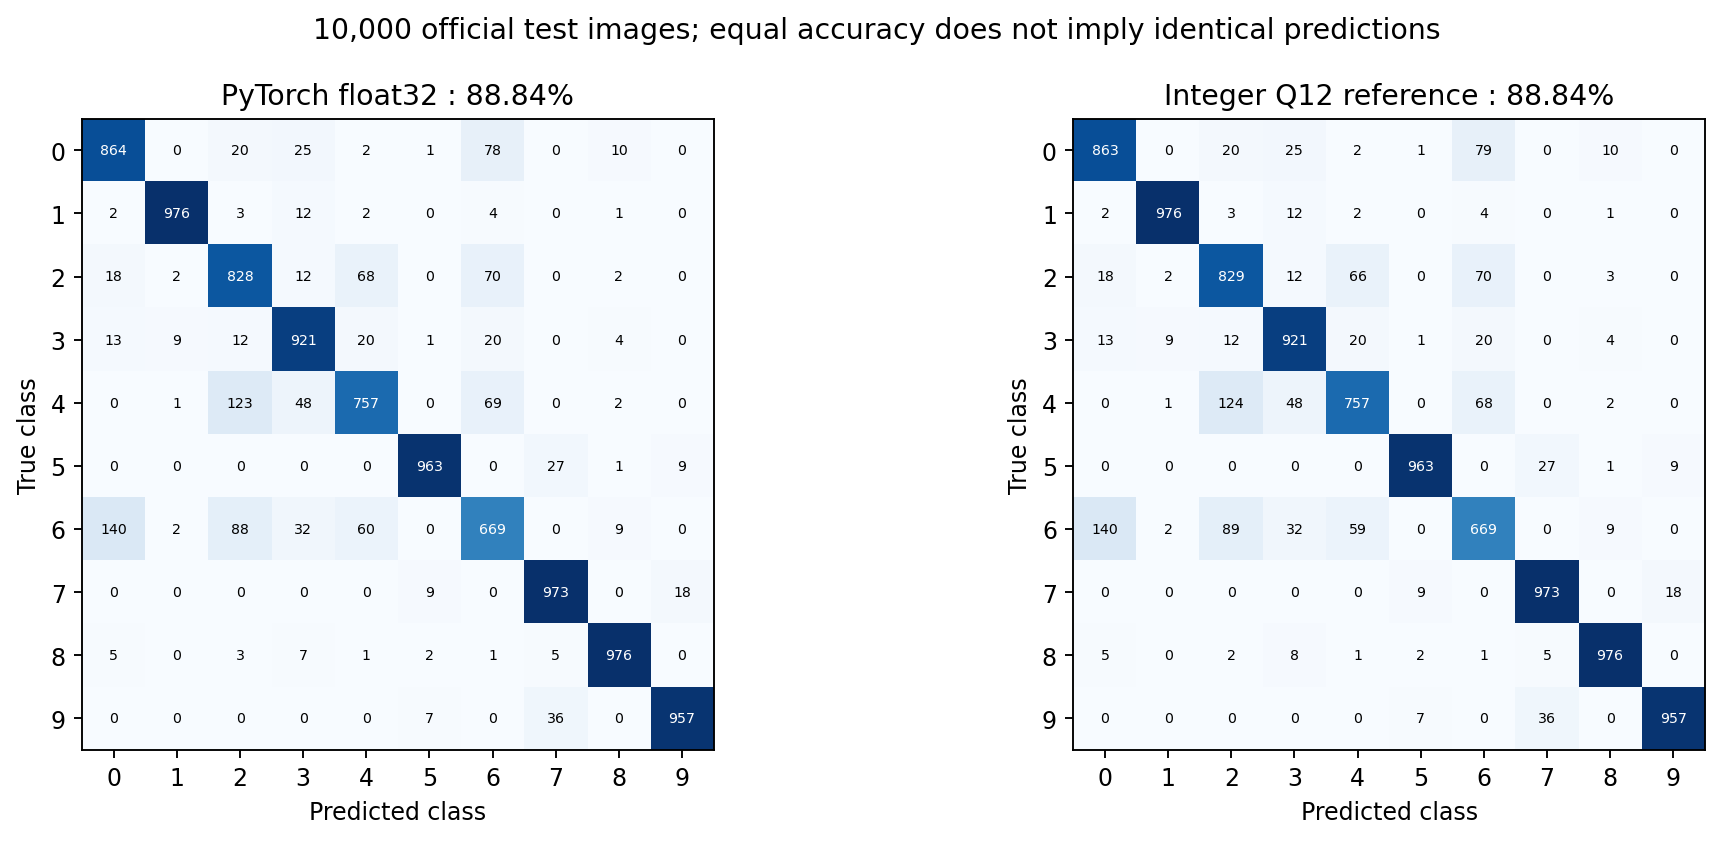

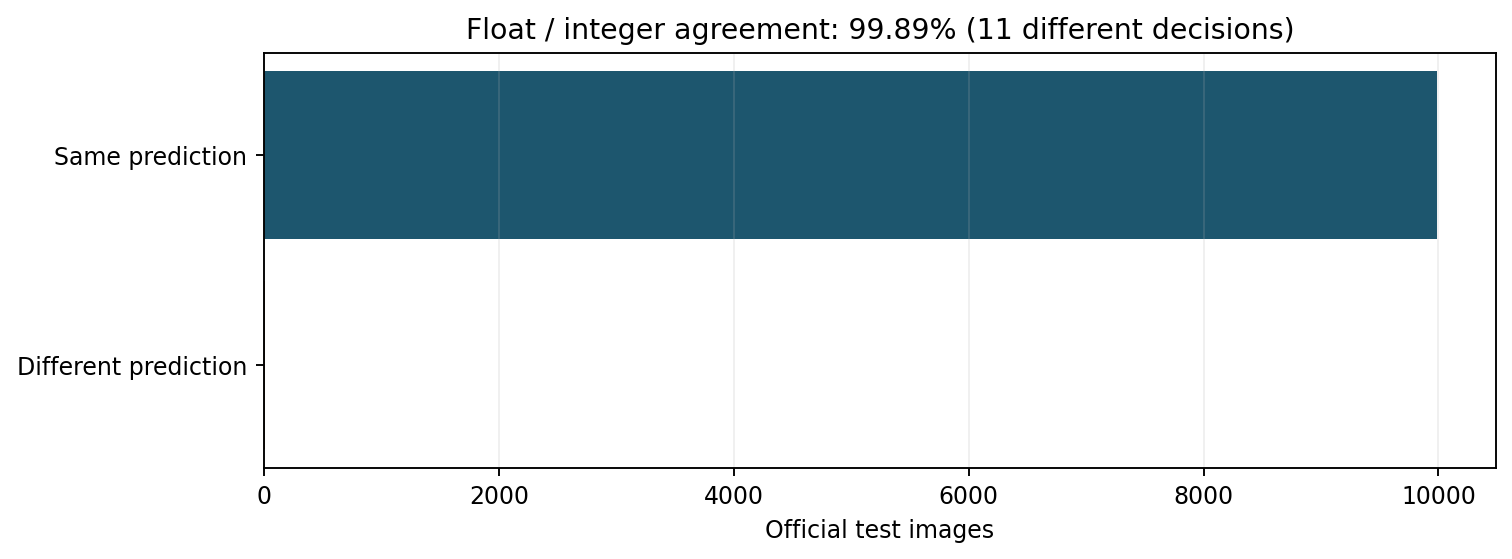

In [7]:
quantization=json.loads((ROOT/'results/software/quantization.json').read_text())
display(pd.DataFrame(quantization['accumulator_bounds']))
display(pd.DataFrame([{'tensor':k,'clips':v} for k,v in quantization['weight_bias_clips'].items()]))
for name in ['software/fixed_point.py','scripts/export_evaluate.py']:
    display(Code((ROOT/name).read_text(),language='python'))
for name in ['confusion.png','agreement.png']:
    display(Image(filename=str(ROOT/'results/figures'/name)))


## 6. Memory hierarchy, ownership and interfaces

L2 contains 61,470 16-bit weight words: 122,940 bytes. The separate 236x48-bit bias
ROM contains 1,416 bytes. Tanh and exp ROMs contain 8,194 and 16,388 bytes. Activations
use two 8,192x16-bit banks, 32 KiB total. A source bank is read while a separate
destination bank receives outputs; bank ownership swaps only after a complete layer.
The design never depends on unwritten padded/tail cells.

The bonus L1 data array is exactly 512x16 = 1,024 bytes. It is direct mapped with
64 lines of eight words. Each line adds a seven-bit tag and valid flag: 64 bytes
of metadata outside the data capacity. A hit responds one clock after the request
handshake. A miss fills the line from the same four-cycle L2. L2 response retirement
and the next refill request can share an edge, giving a four-clock refill initiation
interval. The final line issues only valid L2 addresses and supplies zeros for padding.

One frame owns the controller, memories and result state until the final class is
accepted. Start is accepted only on start && start_ready. Pixels, scores and predictions
use independent valid/ready handshakes. Score data/index/logit and the final class
remain stable under downstream stalls. A synchronous active-high reset cancels a
partial frame, an active convolution or a held output. Memory data are not globally
reset; complete writes and masks establish the next frame's live state.


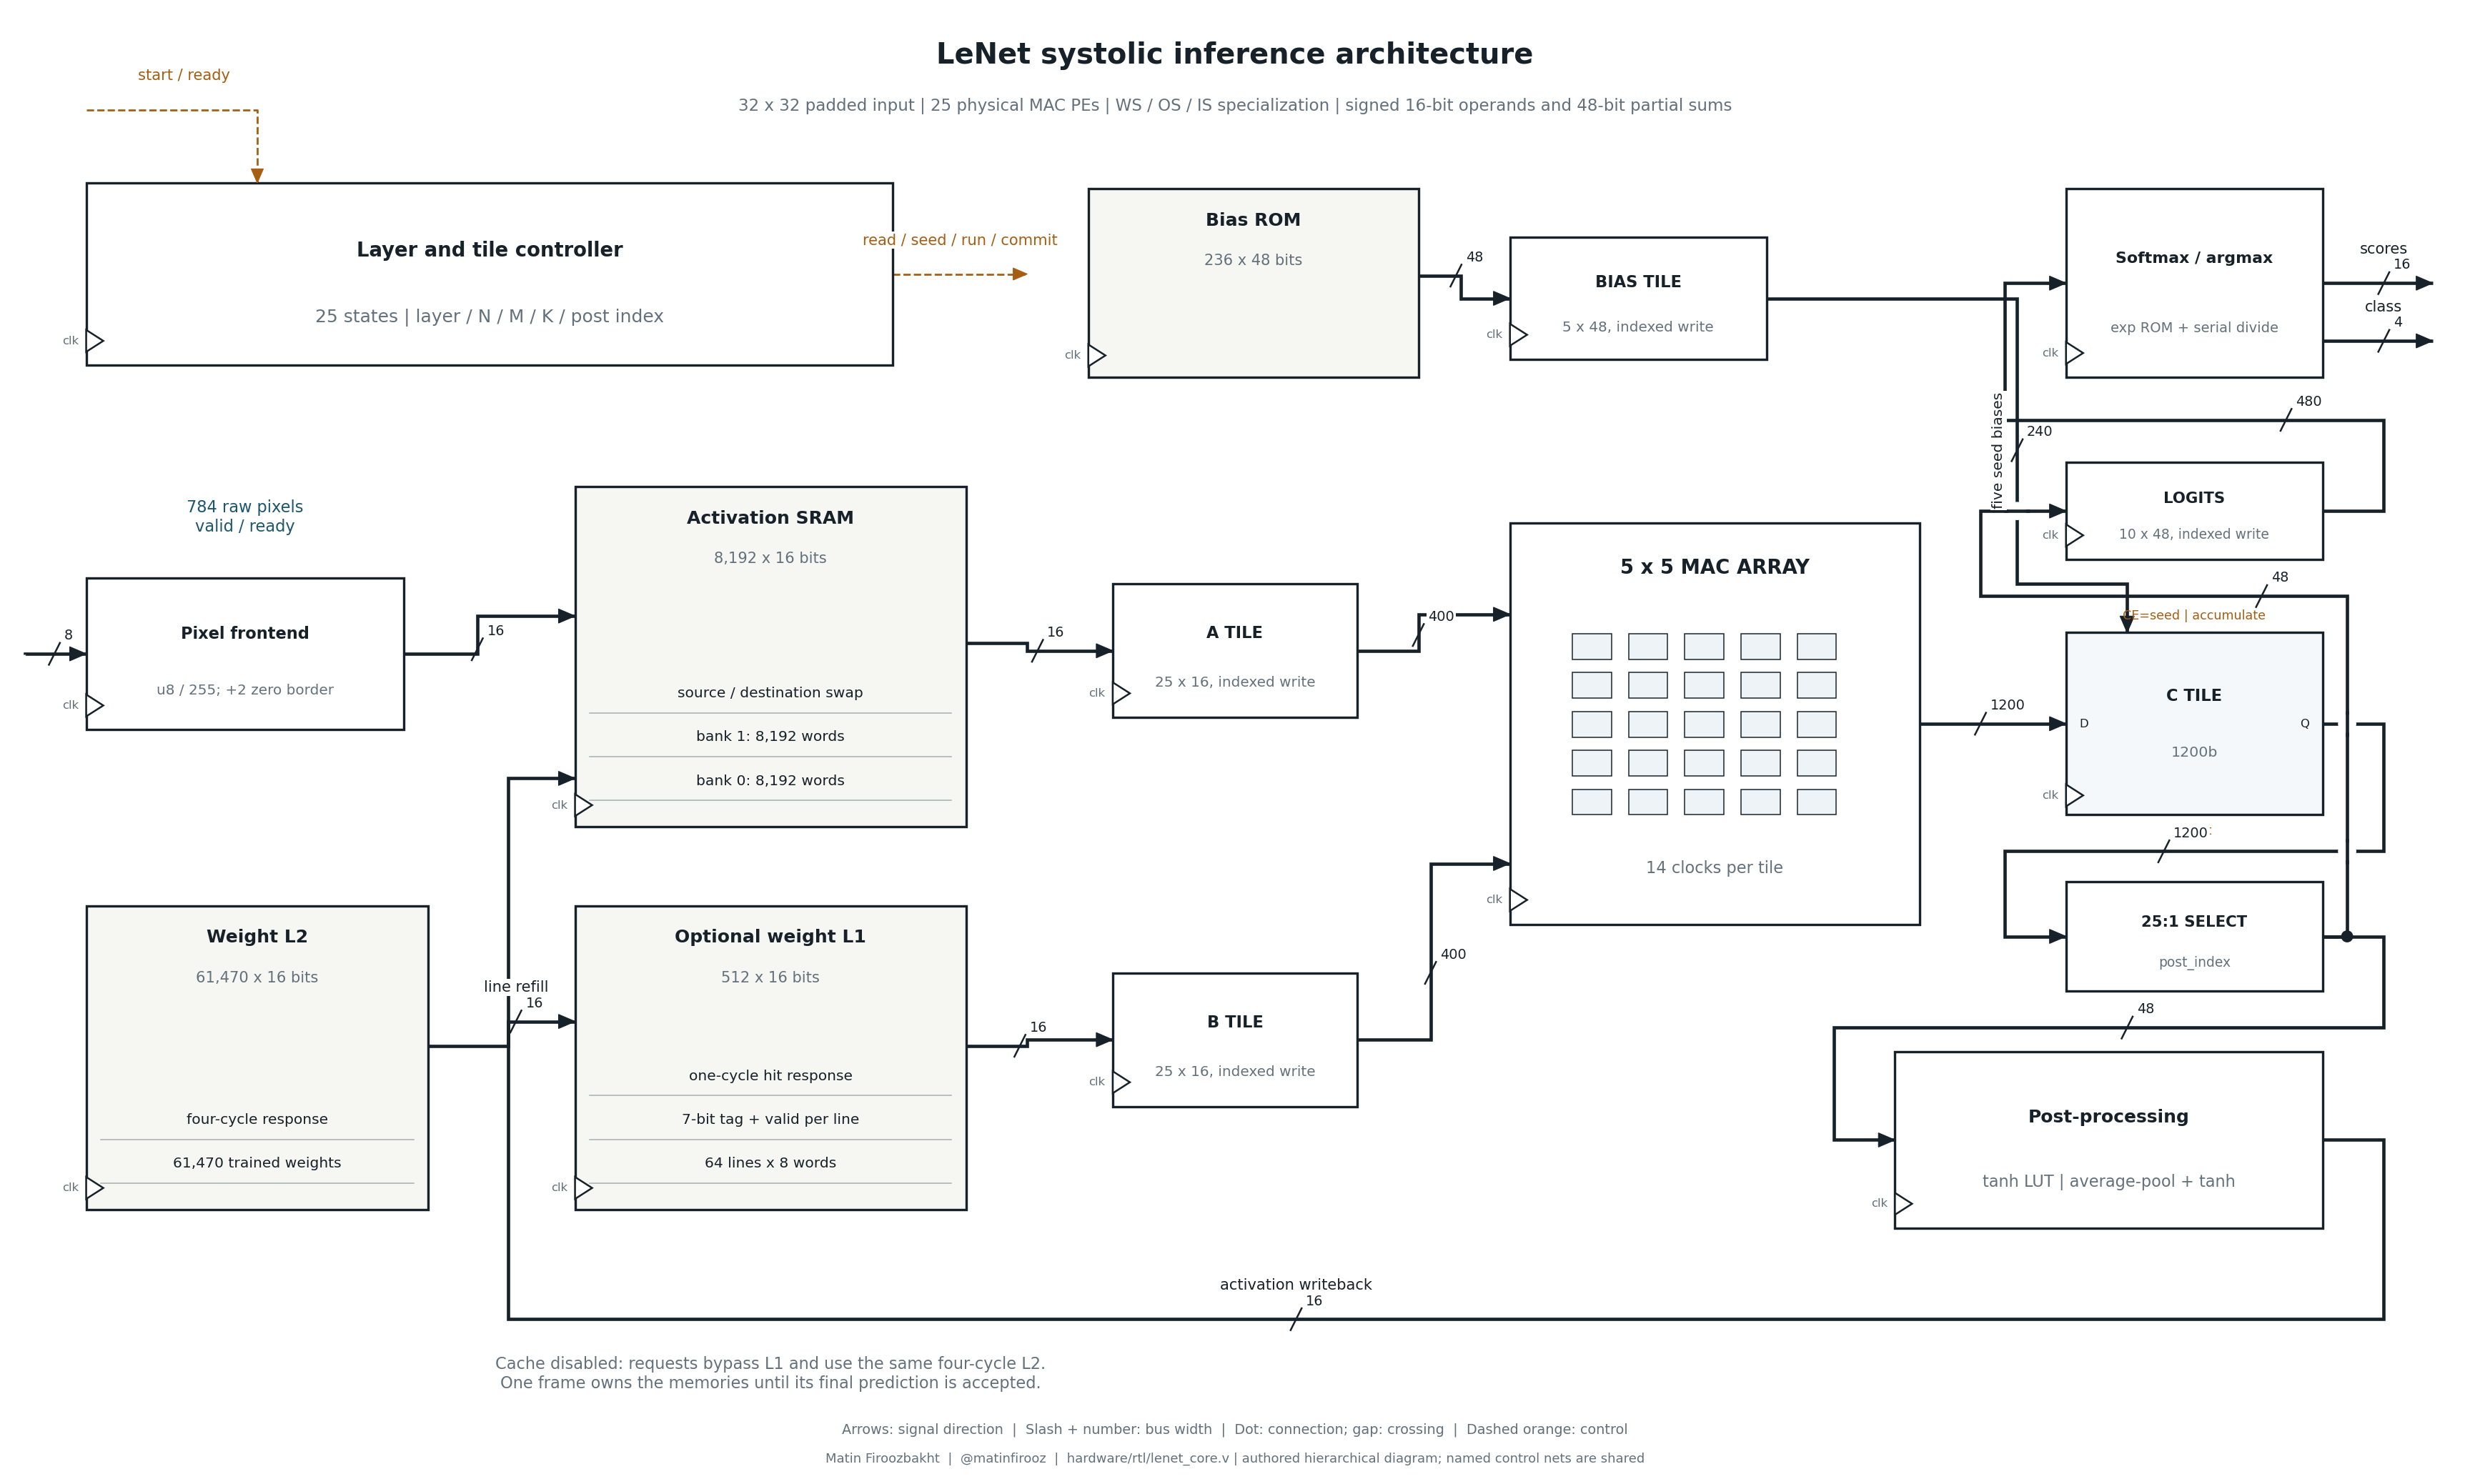

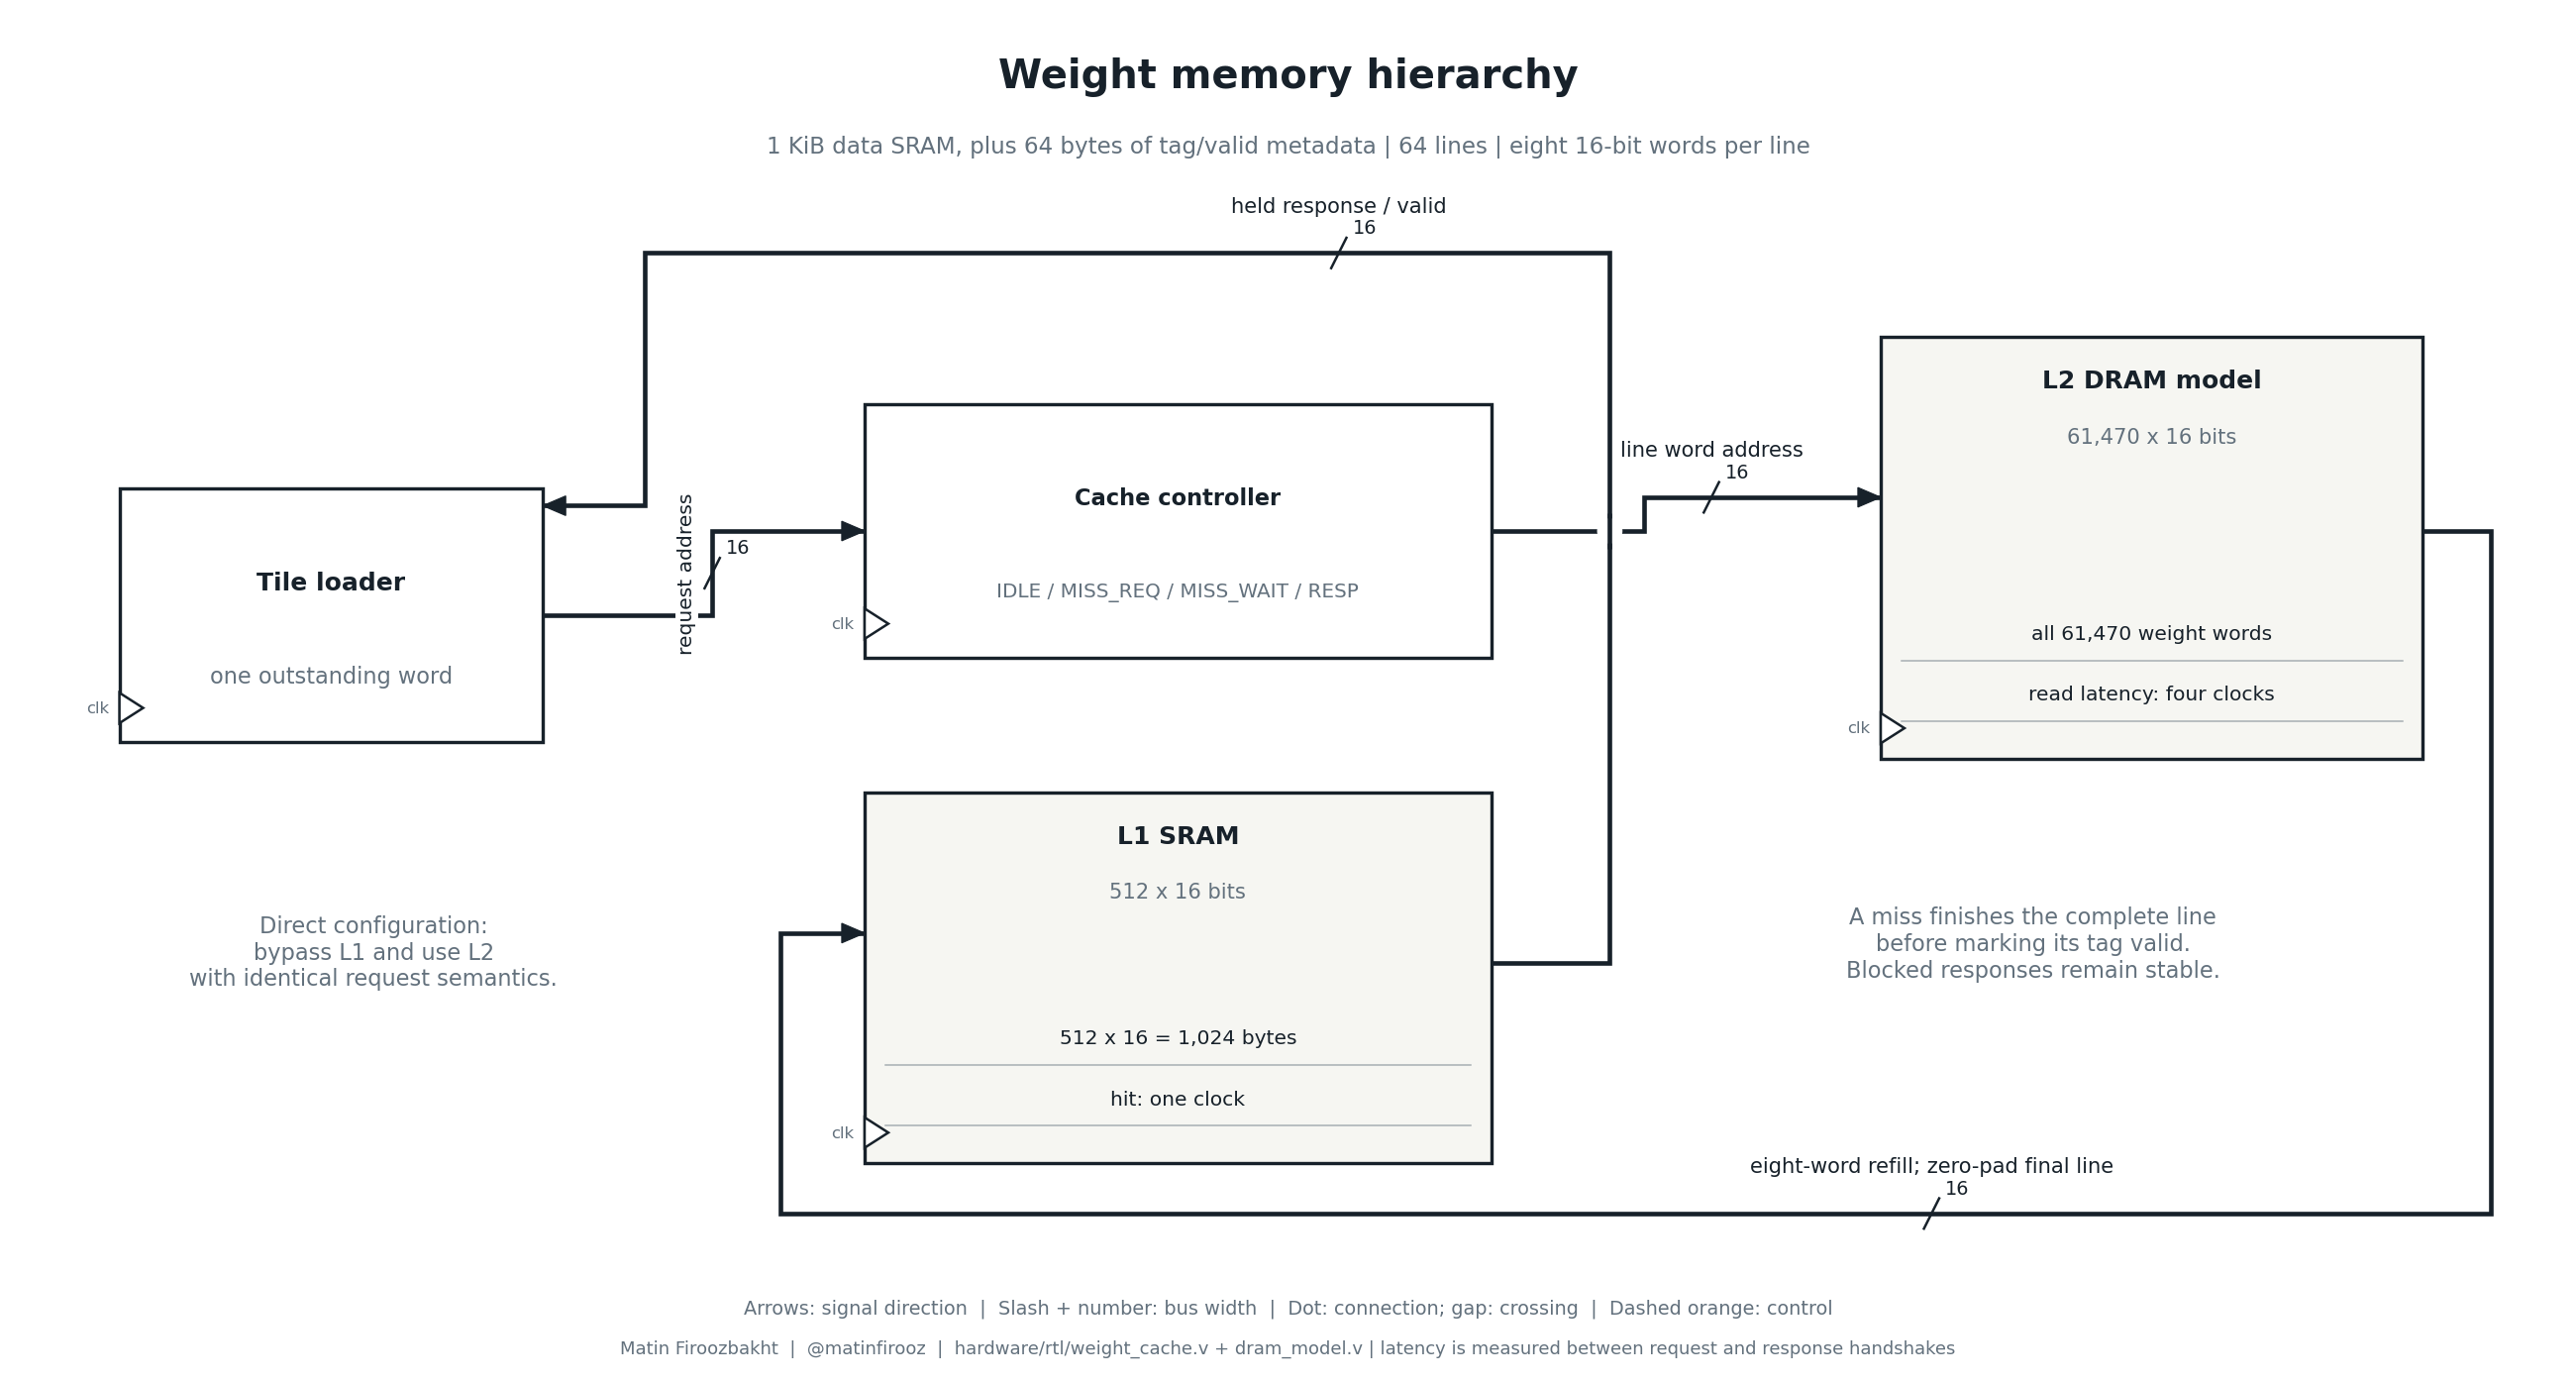

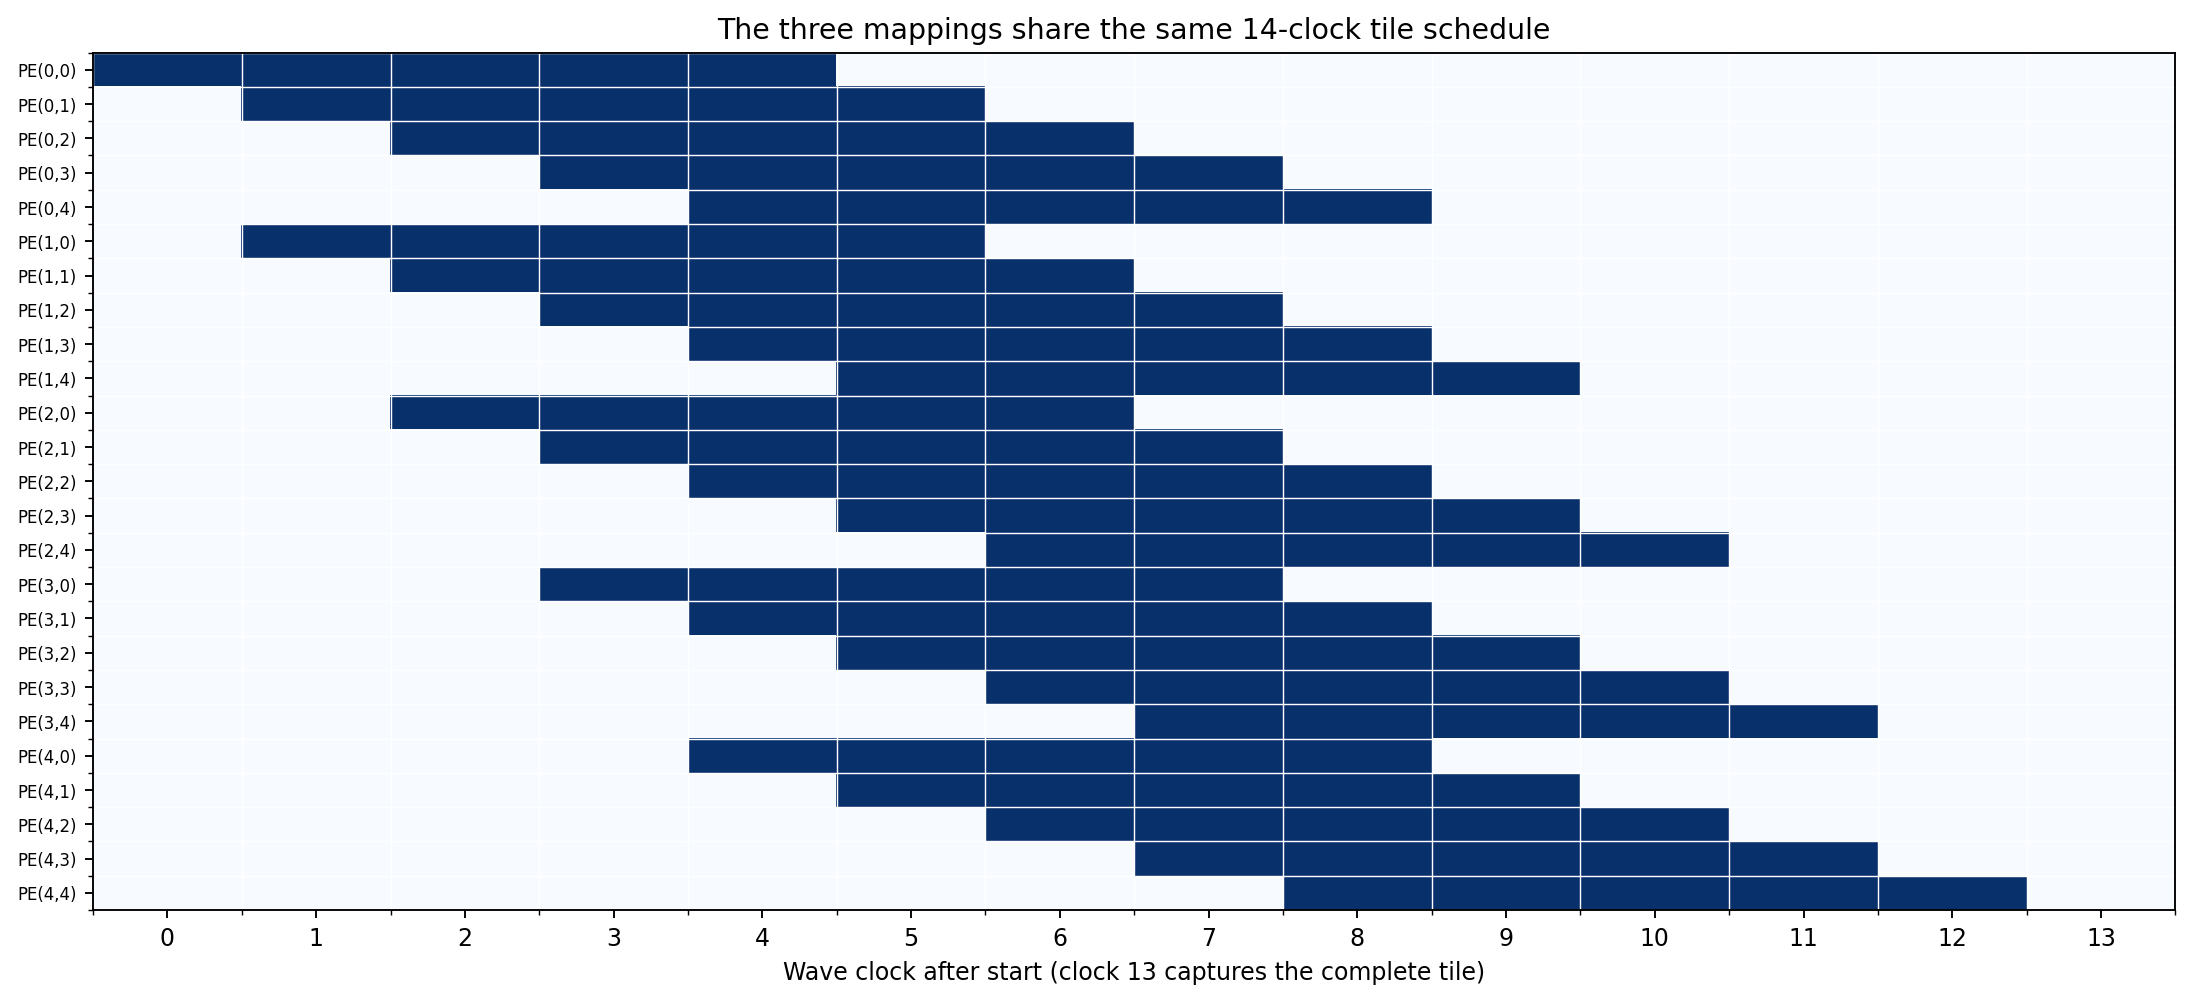

In [8]:
for name in ['architecture.png','memory_hierarchy.png','wavefront.png']:
    display(Image(filename=str(ROOT/'hardware/figures'/name)))


## 7. Actual RTL verification

The official software test uses 10,000 images. The delivered RTL cohort is the first
16 official test images, fixed before checking predictions. Each of six WS/OS/IS
and direct/cache configurations checks 129,344 intermediate values and every
logit, probability and class. The cohort's correctness must not be generalized to
a 10,000-image RTL accuracy claim. A command is provided to generate/simulate a larger
cohort, with per-image reference files keeping testbench memory bounded.

| Dataflow | Weight memory | Compute cycles | Frame cycles | Start interval | RTL cohort |
| --- | --- | --- | --- | --- | --- |
| WS | L2 only | 1,101,438 | 1,103,246 | 1,103,248 | 16/16 |
| WS | 1 KiB L1 + L2 | 1,082,295 | 1,084,103 | 1,084,105 | 16/16 |
| OS | L2 only | 1,101,438 | 1,103,246 | 1,103,248 | 16/16 |
| OS | 1 KiB L1 + L2 | 1,082,295 | 1,084,103 | 1,084,105 | 16/16 |
| IS | L2 only | 1,101,438 | 1,103,246 | 1,103,248 | 16/16 |
| IS | 1 KiB L1 + L2 | 1,082,295 | 1,084,103 | 1,084,105 | 16/16 |

Additional regressions include 60 signed matrix pairs across all three physical
arrays, 1,000 divider cases, 128 tanh/pool cases, 20 softmax distributions with ties,
negative logits and full signed extremes, 126 memory reads per memory mode plus
an interrupted miss, and a complete restarted/stalled inference. Cache tests cover
conflicts, held responses, one-clock hits, four-clock L2 responses and final-line bounds.
Protocol tests cover partial-input/convolution reset cancellation, softmax reset,
score stalls, held predictions and a start pulse while busy. Actual logs and hashes
are in results/hardware/verification.json; no software cycle model is substituted
for these HDL executions.

Generic Yosys checks cover all three array cores and all six complete top-level
specializations. Each retains 25 signed 16x16 PE multipliers, with no inferred latches
and passing hierarchy/connectivity checks. These are generic synthesis results,
not device-specific LUT/DSP/BRAM counts or routed timing.


In [9]:
if RUN_RTL:
    subprocess.run([sys.executable,'scripts/run_verification.py','--samples','16','--jobs','3'],cwd=ROOT,check=True)
    subprocess.run([sys.executable,'scripts/run_generic_synthesis.py'],cwd=ROOT,check=True)
from software.evidence import load
evidence=load(ROOT)
print('Source/ROM/dataset hashes match actual RTL and generic synthesis evidence.')
display(pd.DataFrame([{'case':case['name'],'status':case['status'],'full_inferences':len(case['frames'])} for case in evidence['rtl']['cases']]))
for case in evidence['rtl']['cases']:
    for message in case['pass_messages']:print(message)
display(pd.DataFrame([{'top':case['top'],'cache':case['cache_enable'],'PE_multipliers':len(case['compute_pe_multipliers']),'generic_memories':case['generic_memories'],'inferred_latches':case['inferred_latches']} for case in evidence['generic']['cases']]))


Source/ROM/dataset hashes match actual RTL and generic synthesis evidence.
PASS arrays: 60 signed matrices x 25 outputs x 3 physically distinct dataflows; latency=14 clocks
PASS weight_memory cache=0 reads=126 plus cancelled miss; L2=4 clocks; L1 hit=1 clock; response holds; conflict/tail/reset checked
PASS weight_memory cache=1 reads=126 plus cancelled miss; L2=4 clocks; L1 hit=1 clock; response holds; conflict/tail/reset checked
PASS numerics: 1000 restoring divisions; 128 widened tanh/average-pool cases including signed 48-bit extremes
PASS softmax: 20 distributions, negative logits/ties/extremes, lossless score stalls, held predictions and reset
PASS full_network mode=0 cache=0 stalls=0 samples=16 correct=16 intermediate_checks=129344
PASS full_network mode=0 cache=1 stalls=0 samples=16 correct=16 intermediate_checks=129344
PASS full_network mode=1 cache=0 stalls=0 samples=16 correct=16 intermediate_checks=129344
PASS full_network mode=1 cache=1 stalls=0 samples=16 correct=16 inter

,case,status,full_inferences
0,arrays,passed,0
1,memory_direct,passed,0
2,memory_cache,passed,0
3,numerics,passed,0
4,softmax,passed,0
5,lenet_ws_cache0,passed,16
6,lenet_ws_cache1,passed,16
7,lenet_os_cache0,passed,16
8,lenet_os_cache1,passed,16
9,lenet_is_cache0,passed,16


,top,cache,PE_multipliers,generic_memories,inferred_latches
0,sa_ws_5x5,0,25,0,0
1,sa_os_5x5,0,25,0,0
2,sa_is_5x5,0,25,0,0
3,lenet_top_ws,0,25,8,0
4,lenet_top_ws,1,25,10,0
5,lenet_top_os,0,25,8,0
6,lenet_top_os,1,25,10,0
7,lenet_top_is,0,25,8,0
8,lenet_top_is,1,25,10,0


## 8. Evaluation 1: speed and fairness

**How is hardware inference time calculated?** Count clocks between explicitly
defined handshake events. Compute latency here runs from the final accepted pixel
to final class retirement. Full-frame latency includes input-bank clear and pixel
loading. If the verified operating period is T_ns, latency_ms = cycles*T_ns/1,000,000.
Simulator wall-clock time is verification cost and is not hardware inference latency.

The batch-one PyTorch CPU measurement uses 1 thread, eval mode,
inference_mode, 100 warm-up calls and 500 timed calls per mode. The CPU is
AMD EPYC 9V74 80-Core Processor. Model plus softmax averages **0.351928 ms**;
normalization/padding plus model/softmax averages **0.422177 ms**.
The model-only median is 0.288385 ms and p95 is 0.610215 ms.
Host load and timing variability remain visible in the supplied samples.

The following hardware numbers are **projections at the 100 MHz target**, derived
from actual RTL cycles. They are not achieved-frequency or measured-board timings.

| Dataflow | Cache | Projected latency ms | Projected images/s | Input payload Mbit/s |
| --- | --- | --- | --- | --- |
| WS | 0 | 11.01438 | 90.641 | 0.568503 |
| WS | 1 | 10.82295 | 92.242 | 0.578542 |
| OS | 0 | 11.01438 | 90.641 | 0.568503 |
| OS | 1 | 10.82295 | 92.242 | 0.578542 |
| IS | 0 | 11.01438 | 90.641 | 0.568503 |
| IS | 1 | 10.82295 | 92.242 | 0.578542 |

**Why is a direct software/hardware speed ratio unfair?** The CPU executes float32
with its cache/vector implementation, while RTL uses Q12 and lookup approximations.
CPU model-only timing excludes input transfer; the full hardware transaction includes
zero-fill/loading and a single-frame controller. The L2 model specifies latency but
does not model a complete DDR controller, burst bandwidth, refresh or clock crossings.
The FPGA frequency is unverified. CPU/FPGA transfer and launch costs are also absent
from an accelerator-board end-to-end measurement. Those scopes must be reported
instead of treating the two table columns as equivalent workloads/platforms.

**How should accelerators be compared fairly?** Use the same checkpoint, acceptable
accuracy, numerical precision, dataset cohort, batch size and timing scope. Use the
same FPGA/technology, clock constraints, memory capacity, latency/bandwidth and
implementation effort. Measure achieved feasible clocks with setup/hold, clock-coverage
and DRC checks, then time identical end-to-end transfers. Report area/resources,
latency, sustained initiation interval, energy per image and accuracy together.
For dataflows in this project the array count, arithmetic, software model and external
schedule are held fixed; only stationary mapping and the explicitly labeled cache
configuration vary.


## 9. Evaluation 2: throughput and power

Throughput uses the measured **start-to-start initiation interval**, not only the
first-frame latency. This serial frame owner needs two admission/retirement clocks
beyond a no-stall frame latency. The testbench records start intervals directly.
At an actually verified frequency f, images_per_second = f / II.

One raw input image carries 28*28*8 = **6,272 payload bits**. The reported input
throughput is 6272*f/II bits/s. Counting the padded 32*32*16 internal representation
would instead use 16,384 bits/image and must be labeled as a different convention.
The ten Q16 scores plus four-bit class carry 164 output payload bits/image, so output
payload throughput is 164*f/II. Internal reuse traffic is not counted as new input bits.

Vivado is unavailable here. For each of the six configurations, device utilization,
routed setup/hold slack, feasible clock, total on-chip power and routed throughput
remain null/not_run. The provided flow performs out-of-context synthesis, placement,
routing and report/checkpoint generation with identical constraints. Power is vectorless
unless matching SAIF activity is supplied and its annotation coverage inspected.

**Which dataflow has the best throughput?** At the same feasible clock and memory
mode, the measured schedules tie. A routed frequency difference could change the
ranking, but it has not been measured. **Which is most power-efficient?** There is
no defensible measured winner without power/activity reports. Stationarity explains
different operand/partial-sum movement but is not sufficient evidence of lower total
on-chip power. Energy_per_image = total_power_watts / images_per_second; dynamic
and total power, temperature, voltage and activity assumptions must be consistent.


## 10. Bonus: measured two-level-memory effect

The cache accepts the same 130,470 weight requests per image. It records
119,189 hits and 90,246 L2 reads instead of 130,470, a
**30.83% reduction in L2 word traffic**. Compute latency changes from
1,101,438 to 1,082,295 clocks: **1.017687x** at an equal clock.
The measured improvement is limited because refill/tag/control costs, compulsory
weights and direct-mapped conflicts remain. A high hit ratio alone is not a latency
result; the report uses complete HDL transaction counts. All three dataflows have
the same cache result under their common memory request schedule.

The 1 KiB capacity is data SRAM; the separate tag/valid metadata and controller
state are explicitly accounted for. Cache, pipeline and frame state are reset-safe.
Every bonus configuration is numerically identical to its uncached integer counterpart
on the tested RTL cohort.


Hardware timing columns are target-clock projections, not routed device measurements.


,dataflow,cache,samples,correct,compute_cycles,transaction_cycles,ii_cycles,l2_reads,requests,hits,projected_latency_ms_at_100MHz,projected_images_s_at_100MHz,projected_input_Mbit_s_at_100MHz,routed_images_s,power_watts
0,WS,0,16,16,1101438,1103246,1103248,130470,130470,0,11.01438,90.641451,0.568503,None,None
1,WS,1,16,16,1082295,1084103,1084105,90246,130470,119189,10.82295,92.241988,0.578542,None,None
2,OS,0,16,16,1101438,1103246,1103248,130470,130470,0,11.01438,90.641451,0.568503,None,None
3,OS,1,16,16,1082295,1084103,1084105,90246,130470,119189,10.82295,92.241988,0.578542,None,None
4,IS,0,16,16,1101438,1103246,1103248,130470,130470,0,11.01438,90.641451,0.568503,None,None
5,IS,1,16,16,1082295,1084103,1084105,90246,130470,119189,10.82295,92.241988,0.578542,None,None


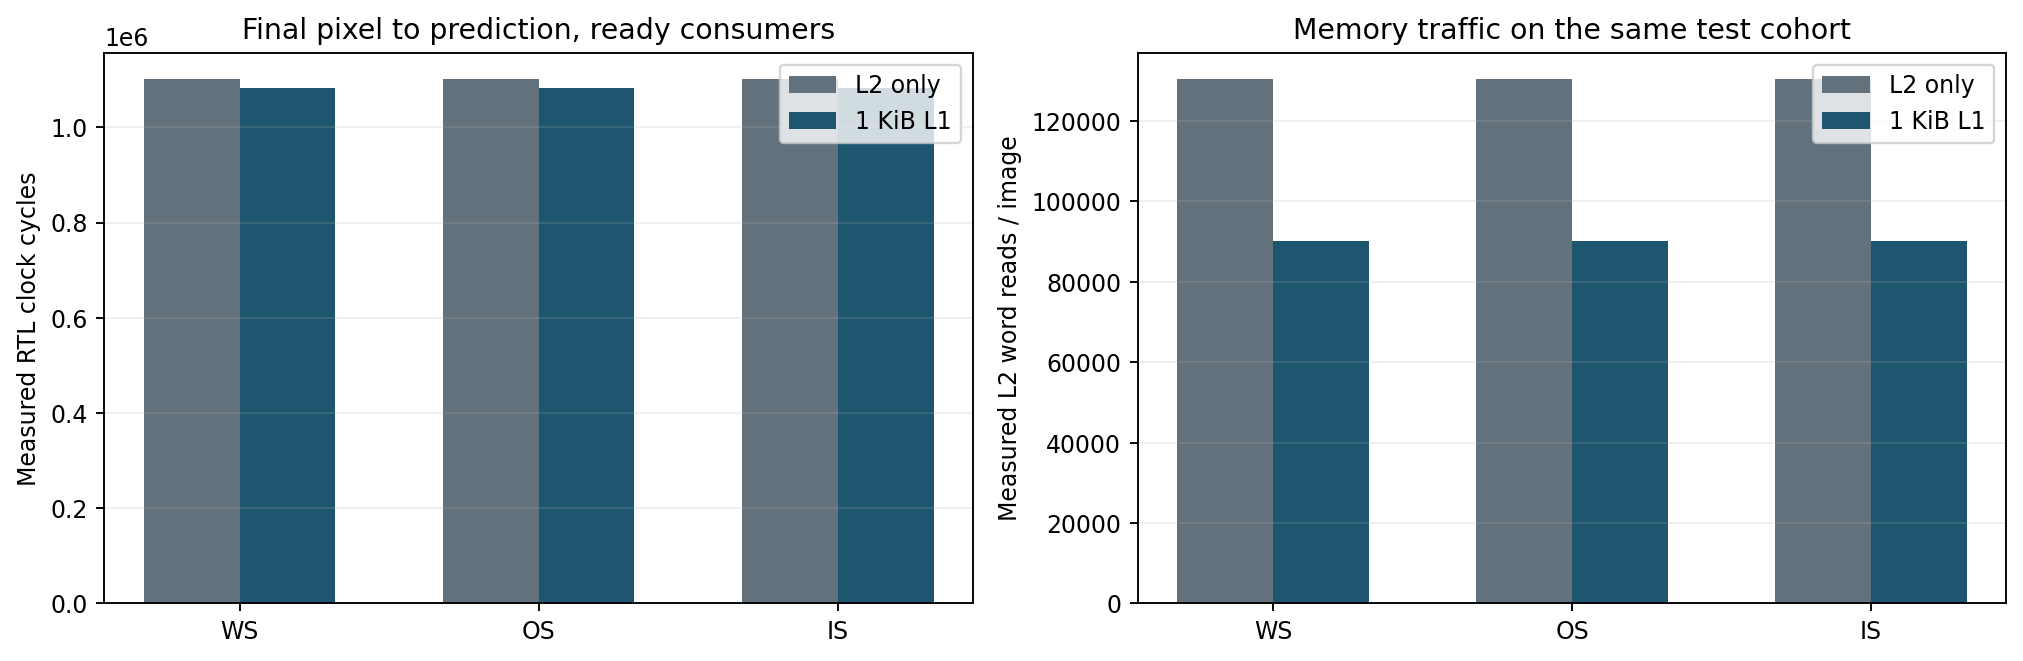

,mean_ms,median_ms,p5_ms,p95_ms
model_only,0.351928,0.288385,0.246048,0.610215
normalize_pad_model,0.422177,0.354875,0.292791,0.739074


In [10]:
evaluation=json.loads((ROOT/'results/evaluation.json').read_text())
display(pd.DataFrame(evaluation['hardware']))
display(Image(filename=str(ROOT/'results/figures/cache_evaluation.png')))
benchmark=json.loads((ROOT/'results/software/benchmark.json').read_text())
display(pd.DataFrame([{key:value for key,value in result.items() if key!='samples_ms'} for result in benchmark['results'].values()],index=list(benchmark['results'])))
print('Hardware timing columns are target-clock projections, not routed device measurements.')


## 11. Reproduction and evidence limits

Install requirements, open the notebook, and use the commands in README.md. Retraining
or editing verified RTL/ROMs requires re-export and fresh simulation. The evidence
checker rejects mismatched hashes. The shipped checkpoint and full dataset permit
offline reproduction; the optional download script verifies official checksums.

The technical content is complete for the supplied requirements. Actual Vivado
implementation metrics and Vivado schematic screenshots require running the included
flow on a machine with that tool. The authored SVG/PNG diagrams document the real
RTL, and are identified as authored figures. No mapped-resource, clock-closure or
power result is invented.


In [11]:
subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=ROOT,check=True,capture_output=True,text=True)
assert len(list((ROOT/'hardware/rtl').glob('*.v')))==26
assert len(raw)==10000 and len(labels)==10000
assert evaluation['rtl_evidence_current'] and evaluation['generic_evidence_current']
print('All eight Python arithmetic/data tests pass. All 26 modules and complete answers are present.')
display(Markdown((ROOT/'README.md').read_text()))


All eight Python arithmetic/data tests pass. All 26 modules and complete answers are present.


# LeNet Systolic Inference

**Matin Firoozbakht** | [@matinfirooz](https://github.com/matinfirooz)

A complete Fashion-MNIST classifier with a trained PyTorch LeNet, an integer reference,
and **three physical 5x5 systolic dataflows: WS, OS and IS**. The 26 RTL modules implement
the full network: zero padding, convolutions, average pooling, tanh, dense layers,
softmax and held prediction outputs. A **1 KiB SRAM cache** and a **four-cycle L2 memory**
provide two reproducible weight-memory configurations.

![Hardware architecture](hardware/figures/architecture.png)

## Verified results

| Implementation | Official test images | Correct | Accuracy |
| --- | --- | --- | --- |
| PyTorch float32 | 10000 | 8884 | 88.84% |
| Integer Q12 reference | 10000 | 8884 | 88.84% |

The float/integer prediction agreement is **99.89%**;
11 decisions differ despite the equal aggregate accuracy.
Weights and biases have **0 clipping events** during export.

| Dataflow | Weight memory | Compute cycles | Frame cycles | Start interval | RTL cohort |
| --- | --- | --- | --- | --- | --- |
| WS | L2 only | 1,101,438 | 1,103,246 | 1,103,248 | 16/16 |
| WS | 1 KiB L1 + L2 | 1,082,295 | 1,084,103 | 1,084,105 | 16/16 |
| OS | L2 only | 1,101,438 | 1,103,246 | 1,103,248 | 16/16 |
| OS | 1 KiB L1 + L2 | 1,082,295 | 1,084,103 | 1,084,105 | 16/16 |
| IS | L2 only | 1,101,438 | 1,103,246 | 1,103,248 | 16/16 |
| IS | 1 KiB L1 + L2 | 1,082,295 | 1,084,103 | 1,084,105 | 16/16 |

**RTL scope:** each of the six configurations checks the same 16 official test images,
all 8,084 intermediate activations per image, all ten logits, all ten probabilities
and the class. The 10,000-image accuracy above is measured by PyTorch and the integer
reference; it is not presented as a 10,000-image RTL simulation result. Additional tests
exercise signed extremes, cache conflicts, memory stalls, score/prediction stalls,
busy-start rejection and reset cancellation.

There are **9 passing generic Yosys synthesis/connectivity checks**.
Vivado mapped resources, routed timing and power are **unmeasured**. A 100 MHz clock
is a constraint target, not an achieved device frequency.

## Network and numeric contract

The network is 32x32 -> C1(6) -> S2 -> C3(16) -> S4 -> C5(120) -> F6(84) -> F7(10).
All convolutions, pooling stages and F6 use tanh; F7 uses softmax. The model contains
**61,706 parameters** and performs **416,520 useful MACs per image**. Inputs are u8/255
with a two-pixel zero border. Weights and activations use signed 16-bit Q12; biases
and accumulators use signed 48-bit Q24. Probability outputs use unsigned Q16.

## Quick start

Use Python 3.12 with the included checkpoint and verified dataset files:

```bash
python -m venv .venv
# Linux/macOS: source .venv/bin/activate
# Windows PowerShell: .venv\Scripts\Activate.ps1
python -m pip install torch==2.5.1 --index-url https://download.pytorch.org/whl/cpu
python -m pip install -r requirements.txt
jupyter lab HW3_Matin_Firoozbakht.ipynb
```

The notebook defaults to the saved checkpoint and measured evidence. Training and
RTL simulation are controlled by explicit switches. No dataset download is needed
when using the included data directory.

## Reproduce results

```bash
# Optional: train 20 epochs on 54,000 images; validate on 6,000.
python scripts/train.py --epochs 20 --threads 4
python scripts/export_evaluate.py --rtl-images 16
python scripts/benchmark_software.py --threads 1
python -m unittest discover -s tests -v
python scripts/run_verification.py --samples 16 --jobs 3
python -m pip install pyosys
python scripts/run_generic_synthesis.py
python scripts/build_report.py
python scripts/render_figures.py
```

Icarus Verilog (`iverilog`, `vvp`) is required for simulation. `IVERILOG`, `VVP` and
`IVL_BASE` support nonstandard installations. Saved evidence is checked against
source, ROM and dataset hashes. A larger RTL cohort can be generated with
`export_evaluate.py --rtl-images N`, then simulated with `run_verification.py --samples N`.

## Vivado

```bash
python scripts/run_vivado.py
python scripts/parse_vivado.py
vivado -mode gui -source hardware/scripts/open_checkpoint.tcl -tclargs ws 0 post_route
```

All six flows use `xc7a100tcsg324-1`, a 10 ns clock target and identical I/O timing
constraints by default. `FPGA_PART`, `CLOCK_PERIOD_NS`, `LENET_DATAFLOW` and
`LENET_CACHE` select an individual build. The flow implements an out-of-context IP
core and writes real checkpoints plus utilization, timing, DRC and power reports.
`LENET_SAIF` and `LENET_SAIF_SCOPE` provide activity for power estimation; otherwise
the estimate is vectorless. Board pin mapping and bitstream programming are separate.

## Documentation and files

- [Complete answers](COMPLETE_ANSWERS.md): every implementation and evaluation question.
- [Executed notebook](HW3_Matin_Firoozbakht.ipynb): software, all RTL sources, figures and measured results.
- [Hardware guide](hardware/README.md), [port catalog](hardware/module_ports.csv) and [architecture metadata](hardware/architecture.json).
- [Specification decisions](docs/SPECIFICATION.md) and original source documents in `docs/`.
- `software/`: PyTorch model/checkpoint, all trained parameters and integer inference.
- `hardware/rtl/`: 26 modules; `hardware/tb/`: arithmetic, memory, full-network and protocol tests.
- `hardware/mem/`: trained ROMs and independent per-image reference traces.
- `results/software/`: full test predictions, training, quantization and CPU timing.
- `results/hardware/`: actual simulation logs, cycle/traffic measurements and generic synthesis.
- `hardware/figures/`, `results/figures/`: editable SVG and high-resolution PNG figures.
- `data/fashion/`: official IDX/gzip files, checksums and the dataset license.

## Interfaces

Start on `start && start_ready`; transfer 784 u8 pixels on `pixel_valid && pixel_ready`.
The core clears the 32x32 input bank and inserts the zero border itself. Ten score
records transfer on `score_valid && score_ready`, followed by a held class on
`prediction_valid && prediction_ready`. Blocked payloads remain stable. Synchronous
active-high reset cancels a frame. All three static top modules expose the same ports.


## Sources

- Provided layer table and task: [HW3 source PDF](docs/HW3_on-campus.pdf).
- Official data, IDX layout, checksums and MIT license: https://github.com/zalandoresearch/fashion-mnist
- PyTorch inference mode: https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad_mode.inference_mode.html
- PyTorch reproducibility: https://docs.pytorch.org/docs/stable/notes/randomness.html
- AMD synthesis command: https://docs.amd.com/r/en-US/ug835-vivado-tcl-commands/synth_design
- AMD timing summary: https://docs.amd.com/r/en-US/ug835-vivado-tcl-commands/report_timing_summary
- AMD power and SAIF: https://docs.amd.com/r/2026.1-English/ug835-vivado-tcl-commands/report_power and https://docs.amd.com/r/en-US/ug835-vivado-tcl-commands/read_saif
